# India Drought Analysis (State: Odisha)
## Notebook 02 (Week 3): Full EDA – distributions, correlations, trends, rankings, seasonality, outliers (Odisha only)

| | |
|---|---|
| **Course** | CUTM1018 – Data Analysis and Visualization with Python |
| **Faculty** | Chandra Sekhar Jena |
| **Students** | Piyush Patnaik (250301370280), Vegulla Virendra Kaushik (250301370267) |
| **Dataset** | Drought Atlas of India 1901–2025, v2 (Chuphal, Kushwaha, Aadhar & Mishra; IIT Gandhinagar / IIT Jodhpur) – https://zenodo.org/records/20368514 |
| **Scope** | Odisha statewide series + 30 Odisha districts |
| **Input** | Cleaned Odisha tables from notebook 01 (`data/clean/`) |

### What this notebook does
In notebook 01 we cleaned the data and saw that, over the full 1901–2025 record, Odisha and every Odisha district have about 16% drought
months. That happens because SPEI is standardised separately for each area (mean 0, standard deviation 1), so the full-period
share cannot be used to rank districts. In this notebook we go further, **inside Odisha only**:

1. **Univariate analysis** – distributions of SPEI-1, SPEI-4 and SPEI-12, skewness, kurtosis and normality tests.
2. **Bivariate analysis / spatial coherence** – how closely the 30 districts follow the Odisha statewide series, correlation between SPEI timescales, and a district–district correlation heatmap.
3. **Trends** – rolling means and the Mann–Kendall trend test (with Sen's slope) for Odisha and each district; decades by district group.
4. **Fair ranking** – early (1901–1960) vs recent (1991–2025) drought share, drought events (run theory), the composite **district ranking**, and a West vs Coastal comparison with statistical tests (plus all four district groups).
5. **Seasonality** – year × month heatmap and season-wise comparisons, also by district group.
6. **Outliers** – IQR and Z-score methods compared.
7. **Key findings.**

A **drought month** is still SPEI-1 ≤ −1 (same as notebook 01). All numbers in the text come from the outputs of this notebook.

## 1. Setup and loading the cleaned data

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import seaborn as sns
from scipy import stats

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 150)
sns.set_theme(style="whitegrid")

# Find the project folder: walk up from the current folder until we see data/clean
# (works if Jupyter was started in the project folder or in notebooks/)
PROJECT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "clean").is_dir()), Path.cwd())
if not (PROJECT / "data" / "clean").is_dir():
    raise FileNotFoundError("Cannot find the project folder (the folder that contains data/clean). Open this notebook from inside the "
                            "unzipped project folder and start Jupyter there - a single notebook file cannot run on its own. "
                            "See RUN_ON_YOUR_DEVICE.md.")
CLEAN = PROJECT / "data" / "clean"
FIG = PROJECT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

DROUGHT_THRESHOLD = -1.0
SPEI_COLS = ["spei_1", "spei_4", "spei_12"]
EARLY = (1901, 1960)    # first 60 years
RECENT = (1991, 2025)   # last 35 years

# Outputs of notebook 01 (Odisha only)
odisha = pd.read_csv(CLEAN / "odisha_month.csv", parse_dates=["date"])
odisha_year = pd.read_csv(CLEAN / "odisha_year.csv")
dist_month = pd.read_csv(CLEAN / "odisha_district_month.csv", parse_dates=["date"])
dist_year = pd.read_csv(CLEAN / "odisha_district_year.csv")

for name, df in [("odisha_month", odisha), ("odisha_year", odisha_year),
                 ("odisha_district_month", dist_month), ("odisha_district_year", dist_year)]:
    print(f"{name:22s} {df.shape}")

odisha_month           (1500, 12)
odisha_year            (125, 17)
odisha_district_month  (45000, 14)
odisha_district_year   (3750, 18)


In [2]:
def period_of(year):
    # Label each year with the period it belongs to
    if year <= EARLY[1]:
        return "1901-1960"
    elif year >= RECENT[0]:
        return "1991-2025"
    else:
        return "1961-1990"


for df in [odisha, dist_month, odisha_year, dist_year]:
    df["period"] = df["year"].apply(period_of)
print(odisha.shape, odisha_year.shape)

(1500, 13) (125, 18)


**Groups of Odisha districts used in this notebook (defined from known geography):**

* **West** (10): Bargarh, Balangir, Boudh, Deogarh, Jharsuguda, Kalahandi, Nuapada, Sambalpur, Subarnapur, Sundargarh – the ten districts covered by the Western Odisha Development Council.
* **Coastal** (6): Balasore, Bhadrak, Kendrapara, Jagatsinghpur, Puri, Ganjam – the six districts with a sea coast on the Bay of Bengal.
* **South** (6): Koraput, Malkangiri, Nabarangpur, Rayagada, Gajapati, Kandhamal – the southern hill districts.
* **North & Central** (8): Angul, Dhenkanal, Keonjhar, Mayurbhanj, Jajpur, Cuttack, Khordha, Nayagarh – the remaining inland districts.
* The statistical test in Section 5 compares **West vs Coastal**; a four-group test is added as a check.

In [3]:
ODISHA_GROUPS = {
    "West": ["Bargarh", "Balangir", "Boudh", "Deogarh", "Jharsuguda", "Kalahandi", "Nuapada",
             "Sambalpur", "Subarnapur", "Sundargarh"],
    "Coastal": ["Balasore", "Bhadrak", "Kendrapara", "Jagatsinghpur", "Puri", "Ganjam"],
    "South": ["Koraput", "Malkangiri", "Nabarangpur", "Rayagada", "Gajapati", "Kandhamal"],
    "North & Central": ["Angul", "Dhenkanal", "Keonjhar", "Mayurbhanj", "Jajpur", "Cuttack", "Khordha", "Nayagarh"],
}
district_group = {d: g for g, names in ODISHA_GROUPS.items() for d in names}

# Safety check: every district has exactly one group
assert set(district_group) == set(dist_month["district"].unique()) and len(district_group) == 30

dist_month["group"] = dist_month["district"].map(district_group)
dist_year["group"] = dist_year["district"].map(district_group)
dist_month.groupby("group")["district"].nunique()

group
Coastal             6
North & Central     8
South               6
West               10
Name: district, dtype: int64

## 2. Univariate analysis: distributions of SPEI

### 2.1 Descriptive statistics, skewness and kurtosis
Skewness = 0 means a symmetric distribution. Kurtosis here is *excess* kurtosis (normal distribution = 0; negative means
lighter tails, i.e. fewer extreme values than a normal curve).

In [4]:
def describe_with_shape(df, label):
    # describe() plus skewness and excess kurtosis for each SPEI column
    rows = []
    for col in SPEI_COLS:
        x = df[col].dropna()
        rows.append({"data": label, "column": col, "n": len(x), "mean": x.mean(), "std": x.std(),
                     "min": x.min(), "median": x.median(), "max": x.max(),
                     "skewness": stats.skew(x), "excess_kurtosis": stats.kurtosis(x)})
    return pd.DataFrame(rows)


shape_table = pd.concat([describe_with_shape(odisha, "Odisha (statewide)"),
                         describe_with_shape(dist_month, "30 Odisha districts pooled")], ignore_index=True)
shape_table.round(3)

,data,column,n,mean,std,min,median,max,skewness,excess_kurtosis
0,Odisha (statewide),spei_1,1500,-0.0,0.996,-2.717,-0.043,2.728,0.027,-0.444
1,Odisha (statewide),spei_4,1497,0.0,0.996,-3.146,0.005,2.683,-0.097,-0.197
2,Odisha (statewide),spei_12,1489,-0.0,0.996,-2.834,0.019,2.926,-0.119,0.058
3,30 Odisha districts pooled,spei_1,45000,0.0,0.996,-3.619,-0.055,3.135,0.149,-0.420
4,30 Odisha districts pooled,spei_4,44910,0.0,0.996,-3.399,-0.010,3.196,-0.000,-0.421
5,30 Odisha districts pooled,spei_12,44670,-0.0,0.996,-3.210,0.008,3.256,-0.018,-0.358


### 2.2 Normality tests
* **Shapiro–Wilk** (good for n ≤ 5000) on the Odisha statewide series (n = 1500 or a little less).
* **D'Agostino K²** (based on skewness and kurtosis) on the statewide series and on the 30 districts pooled (n ≈ 45,000).

H0: the data come from a normal distribution. If p < 0.05 we reject H0.

In [5]:
rows = []
for col in SPEI_COLS:
    x_od = odisha[col].dropna()
    x_all = dist_month[col].dropna()
    rows.append({"column": col,
                 "Odisha Shapiro W": stats.shapiro(x_od).statistic,
                 "Odisha Shapiro p": stats.shapiro(x_od).pvalue,
                 "Odisha K2 p": stats.normaltest(x_od).pvalue,
                 "Districts pooled K2 p (n≈45k)": stats.normaltest(x_all).pvalue})
normality = pd.DataFrame(rows)
normality.round(4)

,column,Odisha Shapiro W,Odisha Shapiro p,Odisha K2 p,Districts pooled K2 p (n≈45k)
0,spei_1,0.9961,0.0007,0.0000,0.0
1,spei_4,0.9978,0.0395,0.0795,0.0
2,spei_12,0.9968,0.0041,0.1500,0.0


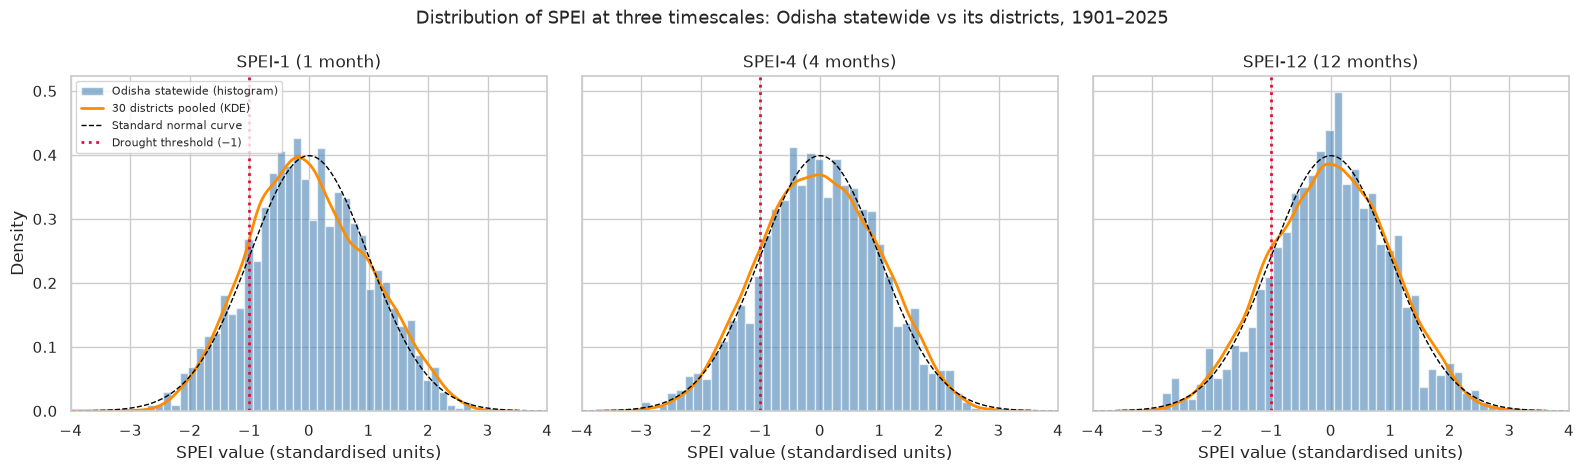

In [6]:
from scipy.stats import norm

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), sharey=True)
xgrid = np.linspace(-4, 4, 200)
for ax, col, title in zip(axes, SPEI_COLS, ["SPEI-1 (1 month)", "SPEI-4 (4 months)", "SPEI-12 (12 months)"]):
    ax.hist(odisha[col].dropna(), bins=40, density=True, color="steelblue", alpha=0.6, label="Odisha statewide (histogram)")
    sns.kdeplot(dist_month[col].dropna(), ax=ax, color="darkorange", linewidth=2, label="30 districts pooled (KDE)")
    ax.plot(xgrid, norm.pdf(xgrid), color="black", linestyle="--", linewidth=1, label="Standard normal curve")
    ax.axvline(DROUGHT_THRESHOLD, color="crimson", linestyle=":", linewidth=2, label="Drought threshold (−1)")
    ax.set_title(f"{title}")
    ax.set_xlabel("SPEI value (standardised units)")
    ax.set_xlim(-4, 4)
axes[0].set_ylabel("Density")
axes[0].legend(fontsize=8, loc="upper left")
fig.suptitle("Distribution of SPEI at three timescales: Odisha statewide vs its districts, 1901–2025", fontsize=13)
plt.tight_layout()
plt.savefig(FIG / "fig06_spei_distributions_hist_kde.png", dpi=150)
plt.show()

**Figure 6 – Distribution of SPEI at three timescales: Odisha statewide (histogram) and the 30 districts pooled (KDE).**

**Interpretation:** All three SPEI timescales are close to a bell shape centred on 0, for the statewide series and for the districts pooled. Skewness is small (between −0.12 and +0.15 in every row of the table) and excess kurtosis is slightly negative for most series (−0.44 for statewide SPEI-1, −0.42 for district SPEI-1), so the tails are a little *lighter* than a normal curve – there are fewer extreme values than a normal distribution would give. The Shapiro–Wilk test still rejects normality for the statewide series (p = 0.0007 for SPEI-1, 0.040 for SPEI-4, 0.004 for SPEI-12), but the D'Agostino K² test does not reject it for statewide SPEI-4 and SPEI-12 (p = 0.080 and 0.150). With about 45,000 district values the pooled test rejects normality for every column. With so much data even tiny differences become "significant", so in practice SPEI is *nearly* normal. This is why we use non-parametric methods (Spearman, Mann–Kendall, Mann–Whitney) next to the usual ones.

## 3. Bivariate analysis and correlations

### 3.1 Odisha statewide series vs its own districts (spatial coherence)
The statewide series is the atlas average for the whole state. How closely does each district follow it? For each district
we calculate the Pearson correlation of monthly SPEI-1 with the statewide value, and also how often a statewide drought month
is a drought month in that district (and the other way round).

In [7]:
state_s = odisha.set_index("date")
rows = []
for d, g in dist_month.groupby("district"):
    g = g.set_index("date")
    both = pd.DataFrame({"dist": g["spei_1"], "state": state_s["spei_1"],
                         "dist_dr": g["drought"], "state_dr": state_s["drought"]})
    r = stats.pearsonr(both["dist"], both["state"])[0]
    r4 = stats.pearsonr(g["spei_4"].dropna(), state_s.loc[g["spei_4"].dropna().index, "spei_4"])[0]
    rows.append({"district": d, "group": district_group[d], "r_spei1": r, "r_spei4": r4,
                 "state_drought_months_also_district_%": 100 * (both["dist_dr"] & both["state_dr"]).sum() / both["state_dr"].sum(),
                 "district_drought_months_also_state_%": 100 * (both["dist_dr"] & both["state_dr"]).sum() / both["dist_dr"].sum()})
coherence = pd.DataFrame(rows).sort_values("r_spei1")
print("Correlation of district SPEI-1 with statewide SPEI-1: min", coherence["r_spei1"].min().round(2), coherence.iloc[0]["district"],
      "| max", coherence["r_spei1"].max().round(2), coherence.iloc[-1]["district"], "| mean", coherence["r_spei1"].mean().round(2))
display(coherence.groupby("group")[["r_spei1", "r_spei4", "state_drought_months_also_district_%", "district_drought_months_also_state_%"]].mean().round(2))
coherence.round(2).head(5)

Correlation of district SPEI-1 with statewide SPEI-1: min 0.69 Malkangiri | max 0.93 Angul | mean 0.84


,r_spei1,r_spei4,state_drought_months_also_district_%,district_drought_months_also_state_%
group,,,,
Coastal,0.81,0.76,67.22,67.92
North & Central,0.87,0.84,72.74,73.63
South,0.80,0.74,70.71,70.01
West,0.87,0.82,72.63,74.49


,district,group,r_spei1,r_spei4,state_drought_months_also_district_%,district_drought_months_also_state_%
20,Malkangiri,South,0.69,0.62,62.96,62.70
2,Balasore,Coastal,0.77,0.73,64.20,61.18
9,Gajapati,South,0.78,0.70,70.78,68.80
19,Koraput,South,0.78,0.73,70.37,68.13
11,Jagatsinghpur,Coastal,0.78,0.72,61.73,64.66


In [8]:
# Pooled: of all district drought months, how many happen while Odisha as a whole is also in drought?
pooled = dist_month.merge(odisha[["date", "drought"]].rename(columns={"drought": "state_drought"}), on="date")
ct = pd.crosstab(pooled["drought"], pooled["state_drought"], rownames=["District drought"], colnames=["Statewide drought"])
print(ct)
print(f"Of {ct.loc[1].sum()} district drought months, {ct.loc[1, 1]} ({ct.loc[1, 1] / ct.loc[1].sum() * 100:.1f}%) were also statewide drought months.")

# How many districts are in drought in the same month? (number of districts out of 30)
n_in_drought = dist_month.groupby("date")["drought"].sum()
print("Months with at least 1 district in drought:", int((n_in_drought >= 1).sum()), "of", len(n_in_drought))
print("Months with 15 or more districts in drought:", int((n_in_drought >= 15).sum()), "| with all 30:", int((n_in_drought == 30).sum()))
print("Statewide drought months with fewer than 10 districts in drought:",
      int(((n_in_drought < 10) & (odisha.set_index("date")["drought"] == 1)).sum()), "of", int(odisha["drought"].sum()))
print("Mean number of districts in drought in a statewide drought month:",
      round(n_in_drought[odisha.set_index("date")["drought"] == 1].mean(), 1))

Statewide drought      0     1
District drought              
0                  35689  2100
1                   2021  5190
Of 7211 district drought months, 5190 (72.0%) were also statewide drought months.
Months with at least 1 district in drought: 685 of 1500
Months with 15 or more districts in drought: 216 | with all 30: 25
Statewide drought months with fewer than 10 districts in drought: 10 of 243
Mean number of districts in drought in a statewide drought month: 21.4


### 3.2 Correlation between SPEI timescales

In [9]:
timescale_corr_odisha = odisha[SPEI_COLS].corr()
timescale_corr_dist = dist_month[SPEI_COLS].corr()
print("Odisha statewide:")
display(timescale_corr_odisha.round(3))
print("Districts pooled:")
display(timescale_corr_dist.round(3))

Odisha statewide:


,spei_1,spei_4,spei_12
spei_1,1.000,0.522,0.300
spei_4,0.522,1.000,0.565
spei_12,0.300,0.565,1.000


Districts pooled:


,spei_1,spei_4,spei_12
spei_1,1.000,0.511,0.276
spei_4,0.511,1.000,0.546
spei_12,0.276,0.546,1.000


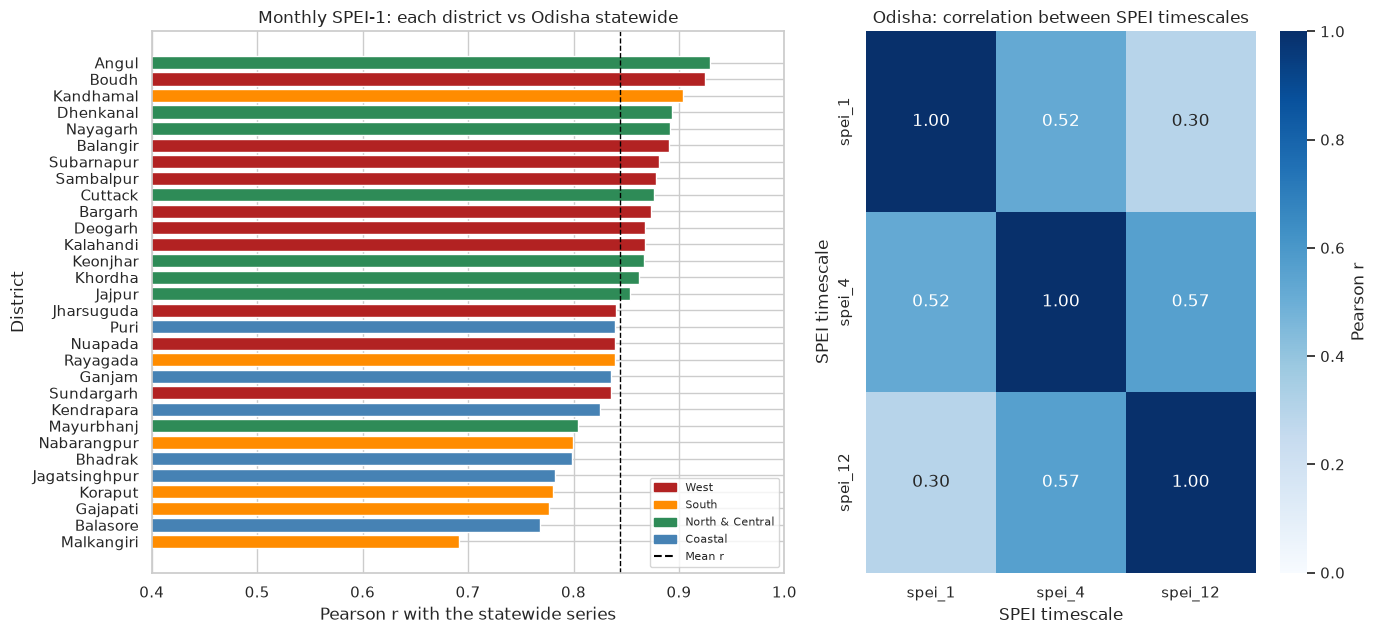

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6.5), gridspec_kw={"width_ratios": [1.3, 1]})
group_colors = {"West": "firebrick", "South": "darkorange", "North & Central": "seagreen", "Coastal": "steelblue"}

# Left: correlation of every district with the statewide SPEI-1
ax = axes[0]
ax.barh(coherence["district"], coherence["r_spei1"], color=coherence["group"].map(group_colors))
ax.axvline(coherence["r_spei1"].mean(), color="black", linestyle="--", linewidth=1, label=f"Mean r = {coherence['r_spei1'].mean():.2f}")
ax.set_xlim(0.4, 1)
ax.set_title("Monthly SPEI-1: each district vs Odisha statewide")
ax.set_xlabel("Pearson r with the statewide series")
ax.set_ylabel("District")
handles = [Patch(color=c, label=g) for g, c in group_colors.items()] + [Line2D([0], [0], color="black", linestyle="--", label="Mean r")]
ax.legend(handles=handles, loc="lower right", fontsize=8)

# Right: correlation between timescales for Odisha
ax = axes[1]
sns.heatmap(timescale_corr_odisha, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, ax=ax,
            cbar_kws={"label": "Pearson r"})
ax.set_title("Odisha: correlation between SPEI timescales")
ax.set_xlabel("SPEI timescale")
ax.set_ylabel("SPEI timescale")
plt.tight_layout()
plt.savefig(FIG / "fig07_odisha_vs_districts_and_timescales.png", dpi=150)
plt.show()

**Figure 7 – Correlation of every district's monthly SPEI-1 with the Odisha statewide series (left) and correlation between SPEI timescales for the statewide series (right).**

**Interpretation:** The districts follow the statewide average closely but not perfectly: the correlation of monthly SPEI-1 with the statewide series is r = 0.84 on average (from 0.69 for Malkangiri to 0.93 for Angul). West (0.87) and North & Central (0.87) districts are closest to the statewide series; the South (0.80) and the Coastal districts (0.81) are further away, so the statewide average mainly reflects the inland north and west. Of the 7,211 district drought months, 5,190 (72.0%) were also statewide drought months, and the other 2,021 were not, so a statewide average hides local droughts. In a statewide drought month on average 21.4 of the 30 districts are in drought, but there were 10 statewide drought months (of 243) with fewer than 10 districts in drought. At least one district was in drought in 685 of the 1,500 months; 216 months had 15 or more districts in drought and 25 months had all 30. The timescales are related but not copies of each other: statewide SPEI-1 vs SPEI-4 r = 0.52, SPEI-4 vs SPEI-12 r = 0.57, and SPEI-1 vs SPEI-12 only 0.30. A single dry month therefore does not mean a dry year.

### 3.3 Correlation heatmap across Odisha districts (spatial coherence)
For each district we take one value per year: the **September SPEI-4**, which measures how dry the June–September monsoon was.
Then we correlate these 125-year series between every pair of the 30 districts, ordered by group (West, South, North & Central, Coastal).

In [11]:
group_names = ["West", "South", "North & Central", "Coastal"]
dist_order = [d for g in group_names for d in ODISHA_GROUPS[g]]
dist_wide = dist_year.pivot(index="year", columns="district", values="monsoon_spei4_sep")[dist_order]
dist_corr = dist_wide.corr()

dpairs = []
for i, a in enumerate(dist_order):
    for b in dist_order[i + 1:]:
        dpairs.append({"a": a, "b": b, "r": dist_corr.loc[a, b], "same_group": district_group[a] == district_group[b]})
dpairs = pd.DataFrame(dpairs)
print("District pairs:", len(dpairs))
print("Mean r over all district pairs:", round(dpairs["r"].mean(), 3))
print("Mean r, same group            :", round(dpairs.loc[dpairs["same_group"], "r"].mean(), 3))
print("Mean r, different group       :", round(dpairs.loc[~dpairs["same_group"], "r"].mean(), 3))
print("Share of pairs with r < 0     :", round((dpairs["r"] < 0).mean() * 100, 1), "%")
print("Weakest pair :", dpairs.nsmallest(1, "r")[["a", "b", "r"]].round(2).values.tolist())
print("Strongest pair:", dpairs.nlargest(1, "r")[["a", "b", "r"]].round(2).values.tolist())

# Average correlation between groups
group_corr = pd.DataFrame(index=group_names, columns=group_names, dtype=float)
for g1 in group_names:
    for g2 in group_names:
        block = dist_corr.loc[ODISHA_GROUPS[g1], ODISHA_GROUPS[g2]].values
        if g1 == g2:
            block = block[~np.eye(len(block), dtype=bool)]   # ignore the diagonal (r = 1)
        group_corr.loc[g1, g2] = block.mean()
group_corr.round(2)

District pairs: 435
Mean r over all district pairs: 0.476
Mean r, same group            : 0.646
Mean r, different group       : 0.423
Share of pairs with r < 0     : 0.5 %
Weakest pair : [['Jharsuguda', 'Gajapati', -0.06]]
Strongest pair: [['Khordha', 'Puri', 0.97]]


,West,South,North & Central,Coastal
West,0.68,0.34,0.50,0.37
South,0.34,0.56,0.35,0.33
North & Central,0.50,0.35,0.68,0.60
Coastal,0.37,0.33,0.60,0.57


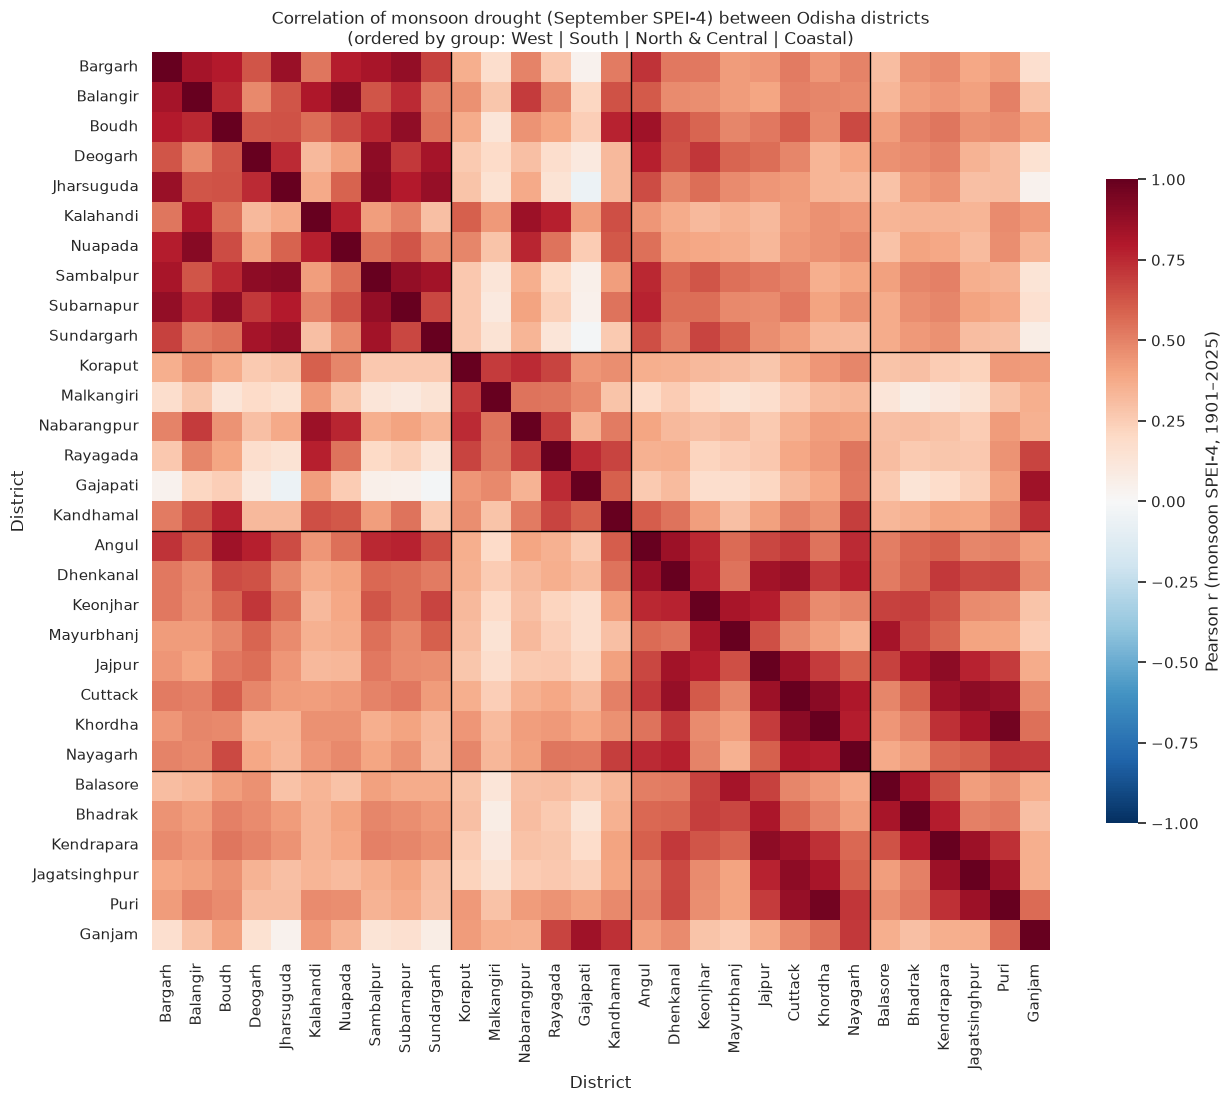

In [12]:
fig, ax = plt.subplots(figsize=(13, 11))
sns.heatmap(dist_corr, cmap="RdBu_r", vmin=-1, vmax=1, center=0, square=True, ax=ax,
            cbar_kws={"label": "Pearson r (monsoon SPEI-4, 1901–2025)", "shrink": 0.7})
for e in np.cumsum([len(ODISHA_GROUPS[g]) for g in group_names])[:-1]:
    ax.axhline(e, color="black", linewidth=1)
    ax.axvline(e, color="black", linewidth=1)
ax.set_title("Correlation of monsoon drought (September SPEI-4) between Odisha districts\n"
             "(ordered by group: West | South | North & Central | Coastal)")
ax.set_xlabel("District")
ax.set_ylabel("District")
plt.tight_layout()
plt.savefig(FIG / "fig08_odisha_district_correlation_heatmap.png", dpi=150)
plt.show()

**Figure 8 – Correlation of monsoon drought (September SPEI-4) between Odisha districts.**

**Interpretation:** Inside Odisha the districts are quite alike (mean r = 0.48 over all 435 district pairs), but there is clear structure. Districts in the same group correlate at r = 0.65 on average, compared with 0.42 between groups. The West block and the North & Central block are the most coherent (r = 0.68 within each), the South hill districts are weakly linked to every other group (0.33–0.35), and West vs Coastal is only 0.37. The inland North & Central districts are closer to the Coastal group (0.60) than the West is (0.37). The strongest pair is Khordha–Puri (r = 0.97) and the weakest is Jharsuguda–Gajapati (r = −0.06); only 0.5% of district pairs (2 of 435) are negatively correlated. This means a monsoon failure in western Odisha does not always hit the coast, and the West vs Coastal split used later makes sense.

## 4. Trends over time

### 4.1 Method
* **Rolling mean:** an 11-year centred moving average smooths the year-to-year ups and downs.
* **Mann–Kendall test:** a non-parametric test for a steady upward or downward trend. It is the same as Kendall's tau
  between *year* and the value, so we use `scipy.stats.kendalltau`. H0: no trend. p < 0.05 → significant trend.
* **Sen's slope** (`scipy.stats.theilslopes`): the median of all pairwise slopes; we report it **per decade**. It is
  robust to outliers. We also show the ordinary linear-regression slope (`linregress`) for comparison.

We test four yearly variables: mean SPEI-1 of the year, September SPEI-4 (monsoon), December SPEI-12 (calendar year)
and the number of drought months in the year.

In [13]:
def trend_test(years, values):
    # Mann-Kendall (Kendall tau vs year), Sen's slope and linear regression slope, both per decade
    mask = ~np.isnan(values)
    years, values = np.asarray(years)[mask], np.asarray(values)[mask]
    tau = stats.kendalltau(years, values)
    sen = stats.theilslopes(values, years)
    lin = stats.linregress(years, values)
    return {"kendall_tau": tau.statistic, "mk_p": tau.pvalue, "sen_slope_per_decade": sen.slope * 10,
            "lin_slope_per_decade": lin.slope * 10, "lin_p": lin.pvalue}


TREND_VARS = {"spei1_mean": "Yearly mean SPEI-1", "monsoon_spei4_sep": "Monsoon (Sep SPEI-4)",
              "annual_spei12_dec": "Calendar year (Dec SPEI-12)", "drought_months": "Drought months per year"}

rows = []
for var, label in TREND_VARS.items():
    rows.append({"area": "Odisha", "variable": label, **trend_test(odisha_year["year"], odisha_year[var])})
trend_main = pd.DataFrame(rows)
trend_main["significant (p<0.05)"] = trend_main["mk_p"] < 0.05
trend_main.round(4)

,area,variable,kendall_tau,mk_p,sen_slope_per_decade,lin_slope_per_decade,lin_p,significant (p<0.05)
0,Odisha,Yearly mean SPEI-1,-0.2181,0.0003,-0.0278,-0.0309,0.0001,True
1,Odisha,Monsoon (Sep SPEI-4),-0.0755,0.2119,-0.0296,-0.0292,0.2403,False
2,Odisha,Calendar year (Dec SPEI-12),-0.0741,0.2206,-0.0312,-0.0409,0.0995,False
3,Odisha,Drought months per year,0.3313,0.0000,0.1667,0.1994,0.0000,True


In [14]:
# The Mann-Kendall test assumes the yearly values are not strongly related to the previous year.
# Check the lag-1 autocorrelation of each Odisha yearly series.
for var, label in TREND_VARS.items():
    print(f"{label:30s} lag-1 autocorrelation = {odisha_year[var].autocorr(lag=1):.3f}")

Yearly mean SPEI-1             lag-1 autocorrelation = 0.115
Monsoon (Sep SPEI-4)           lag-1 autocorrelation = 0.067
Calendar year (Dec SPEI-12)    lag-1 autocorrelation = -0.037
Drought months per year        lag-1 autocorrelation = 0.216


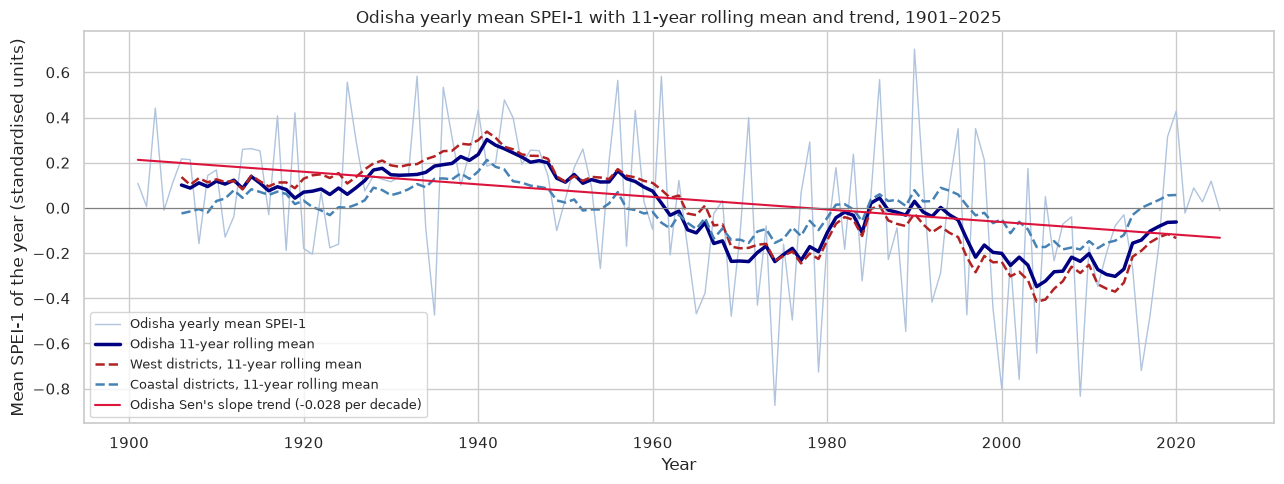

Highest 11-yr rolling mean (Odisha): 0.303 centred on 1941
Lowest 11-yr rolling mean (Odisha) : -0.349 centred on 2004
West: lowest 11-yr rolling mean -0.416 centred on 2004; highest 0.338 centred on 1941; last value -0.134 (centred on 2020)
Coastal: lowest 11-yr rolling mean -0.184 centred on 2009; highest 0.212 centred on 1941; last value 0.057 (centred on 2020)
Odisha last 11-yr rolling mean: -0.063 centred on 2020


In [15]:
od_roll = odisha_year["spei1_mean"].rolling(11, center=True).mean()
sen = stats.theilslopes(odisha_year["spei1_mean"], odisha_year["year"])
# Group averages of the yearly mean SPEI-1 (rolling), to see whether the groups move differently
grp_year = dist_year.groupby(["group", "year"])["spei1_mean"].mean().unstack(0)

fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(odisha_year["year"], odisha_year["spei1_mean"], color="lightsteelblue", linewidth=1,
        label="Odisha yearly mean SPEI-1")
ax.plot(odisha_year["year"], od_roll, color="navy", linewidth=2.5, label="Odisha 11-year rolling mean")
for g in ["West", "Coastal"]:
    ax.plot(grp_year.index, grp_year[g].rolling(11, center=True).mean(), color=group_colors[g], linewidth=1.8,
            linestyle="--", label=f"{g} districts, 11-year rolling mean")
ax.plot(odisha_year["year"], sen.intercept + sen.slope * odisha_year["year"], color="crimson", linewidth=1.5,
        label=f"Odisha Sen's slope trend ({sen.slope * 10:+.3f} per decade)")
ax.axhline(0, color="grey", linewidth=0.8)
ax.set_title("Odisha yearly mean SPEI-1 with 11-year rolling mean and trend, 1901–2025")
ax.set_xlabel("Year")
ax.set_ylabel("Mean SPEI-1 of the year (standardised units)")
ax.legend(loc="lower left", fontsize=9)
plt.tight_layout()
plt.savefig(FIG / "fig09_odisha_rolling_trend_line.png", dpi=150)
plt.show()

# Rolling-mean values at a few points, used in the interpretation
print("Highest 11-yr rolling mean (Odisha):", round(od_roll.max(), 3), "centred on", int(odisha_year.loc[od_roll.idxmax(), "year"]))
print("Lowest 11-yr rolling mean (Odisha) :", round(od_roll.min(), 3), "centred on", int(odisha_year.loc[od_roll.idxmin(), "year"]))
for g in ["West", "Coastal"]:
    r = grp_year[g].rolling(11, center=True).mean()
    print(f"{g}: lowest 11-yr rolling mean {r.min():.3f} centred on {int(r.idxmin())}; highest {r.max():.3f} centred on {int(r.idxmax())}; last value {r.dropna().iloc[-1]:.3f} (centred on {int(r.dropna().index[-1])})")
print("Odisha last 11-yr rolling mean:", round(od_roll.dropna().iloc[-1], 3), "centred on", int(odisha_year.loc[od_roll.last_valid_index(), "year"]))

**Figure 9 – Odisha yearly mean SPEI-1 with 11-year rolling mean (also for the West and Coastal groups) and Sen's slope trend.**

**Interpretation:** Odisha shows a significant drying trend in the **yearly mean SPEI-1** (Mann–Kendall tau = −0.22, p = 0.0003; Sen's slope −0.028 SPEI units per decade, about −0.35 over 125 years) and a significant rise in **drought months per year** (tau = 0.33, p < 0.0001; about +0.17 months per decade). The 11-year rolling mean was highest around 1941 (+0.30) and lowest around 2004 (−0.35), and in the last window (centred on 2020) it is −0.06, back close to zero. The West districts dip deeper (lowest rolling mean −0.42 around 2004) and are still negative at the end (−0.13), while the Coastal group is only −0.18 at its lowest (around 2009) and is back to +0.06. However, the **monsoon (September SPEI-4)** and **calendar-year (December SPEI-12)** indicators for Odisha have *no* significant trend (p = 0.21 and 0.22). So the drying is not mainly a weaker monsoon; it is coming from other months (see Section 6). Lag-1 autocorrelation of the yearly series is small (−0.04 to 0.22), so the Mann–Kendall assumption of roughly independent years is reasonable.

### 4.2 Trend in each Odisha district

In [16]:
rows = []
for district, g in dist_year.groupby("district"):
    for var in ["spei1_mean", "monsoon_spei4_sep", "annual_spei12_dec"]:
        rows.append({"district": district, "group": district_group[district], "variable": var,
                     **trend_test(g["year"], g[var])})
dist_trends = pd.DataFrame(rows)
dist_trends["significant"] = dist_trends["mk_p"] < 0.05

# How many districts have a significant drying (negative) trend for each variable?
summary = dist_trends.assign(sig_drying=(dist_trends["significant"]) & (dist_trends["sen_slope_per_decade"] < 0),
                             sig_wetting=(dist_trends["significant"]) & (dist_trends["sen_slope_per_decade"] > 0))
print("Districts with a significant WETTING trend:")
print(summary.loc[summary["sig_wetting"], ["district", "variable", "kendall_tau", "mk_p"]].round(4).to_string(index=False))
summary.groupby("variable")[["sig_drying", "sig_wetting"]].sum()

Districts with a significant WETTING trend:
  district          variable  kendall_tau   mk_p
  Gajapati monsoon_spei4_sep       0.1367 0.0238
Malkangiri monsoon_spei4_sep       0.1471 0.0150


,sig_drying,sig_wetting
variable,,
annual_spei12_dec,11,0
monsoon_spei4_sep,9,2
spei1_mean,19,0


In [17]:
# Significant drying districts by group (yearly mean SPEI-1)
t1 = dist_trends[dist_trends["variable"] == "spei1_mean"]
t1.assign(sig_drying=t1["significant"] & (t1["sen_slope_per_decade"] < 0)).groupby("group").agg(
    districts=("district", "count"), significant_drying=("sig_drying", "sum"),
    mean_sen_slope=("sen_slope_per_decade", "mean")).round(3)

,districts,significant_drying,mean_sen_slope
group,,,
Coastal,6,0,-0.009
North & Central,8,4,-0.014
South,6,5,-0.026
West,10,10,-0.039


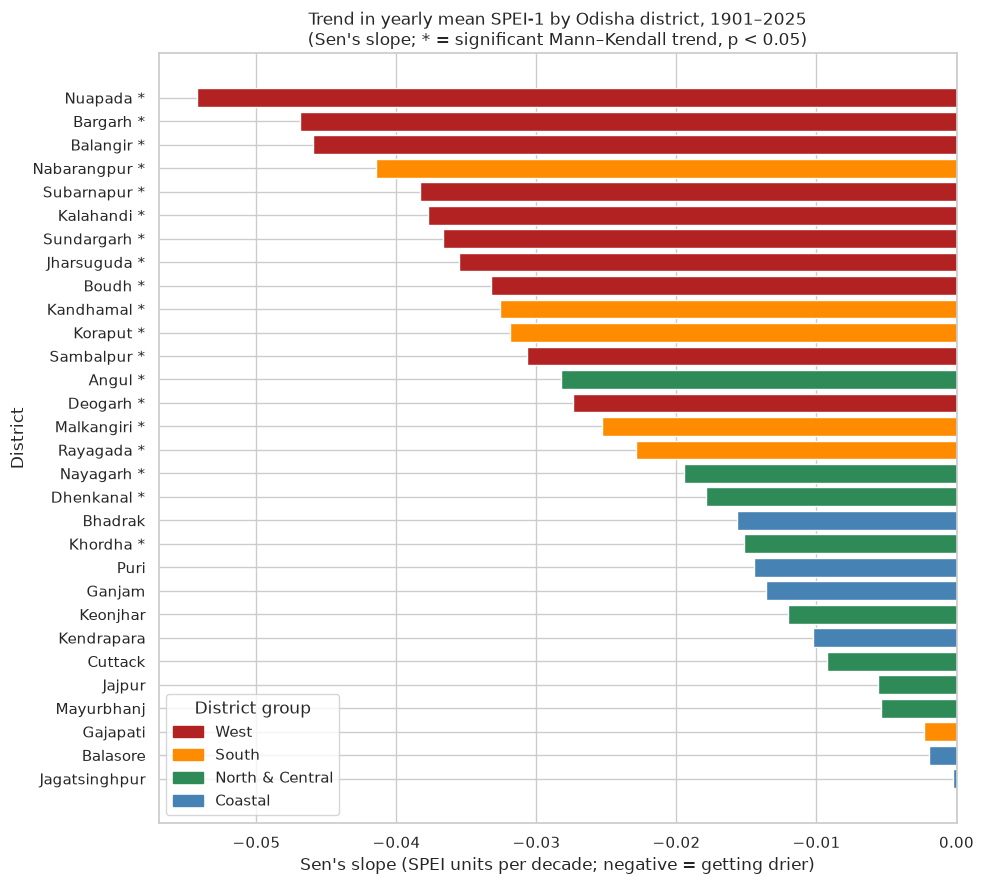

,district,group,kendall_tau,mk_p,sen_slope_per_decade
72,Nuapada,West,-0.3585,0.0000,-0.0543
9,Bargarh,West,-0.2932,0.0000,-0.0469
3,Balangir,West,-0.3301,0.0000,-0.0460
66,Nabarangpur,South,-0.2821,0.0000,-0.0415
84,Subarnapur,West,-0.2405,0.0001,-0.0383
42,Kalahandi,West,-0.2883,0.0000,-0.0378
87,Sundargarh,West,-0.2415,0.0001,-0.0367
39,Jharsuguda,West,-0.2395,0.0001,-0.0355


In [18]:
t1 = dist_trends[dist_trends["variable"] == "spei1_mean"].sort_values("sen_slope_per_decade")

fig, ax = plt.subplots(figsize=(10, 9))
labels = [f"{d} *" if s else d for d, s in zip(t1["district"], t1["significant"])]
ax.barh(labels, t1["sen_slope_per_decade"], color=t1["group"].map(group_colors))
ax.axvline(0, color="black", linewidth=0.8)
# Legend: one coloured box per district group
handles = [Patch(color=c, label=g) for g, c in group_colors.items()]
ax.set_title("Trend in yearly mean SPEI-1 by Odisha district, 1901–2025\n(Sen's slope; * = significant Mann–Kendall trend, p < 0.05)")
ax.set_xlabel("Sen's slope (SPEI units per decade; negative = getting drier)")
ax.set_ylabel("District")
ax.invert_yaxis()
ax.legend(handles=handles, title="District group", loc="lower left")
plt.tight_layout()
plt.savefig(FIG / "fig10_district_trend_bar.png", dpi=150)
plt.show()
t1[["district", "group", "kendall_tau", "mk_p", "sen_slope_per_decade"]].head(8).round(4)

**Figure 10 – Sen's slope of yearly mean SPEI-1 for each Odisha district (* = significant).**

**Interpretation:** 19 of the 30 districts have a significant drying trend in yearly mean SPEI-1 and none has a significant wetting trend. The pattern is very regional: **all 10 West districts** are significant (mean slope −0.039 per decade), 5 of 6 South districts (−0.026), 4 of 8 North & Central districts (−0.014) and **none of the 6 Coastal districts** (−0.009). The steepest drying is in Nuapada (−0.054 per decade, tau = −0.36), Bargarh (−0.047) and Balangir (−0.046). For the monsoon indicator (September SPEI-4) only 9 districts dry significantly and 2 southern districts (Malkangiri and Gajapati) even show a small significant wetting trend; for the calendar-year indicator (December SPEI-12) 11 districts dry significantly. This again shows that the monsoon itself is not the main driver of the drying.

### 4.3 Decade by decade, by district group
A decade-by-decade table of the share of drought months for each district group (30 districts, pooled within the group).
We only use what the atlas contains. **ENSO (El Niño) years are not part of the atlas and we do not add outside data here**, so
no ENSO analysis is done.

In [19]:
decade_group = (dist_month.groupby(["decade", "group"])["drought"].mean().unstack() * 100)[group_names]
decade_group["Odisha statewide"] = odisha.groupby("decade")["drought"].mean() * 100
decade_group.round(1)

group,West,South,North & Central,Coastal,Odisha statewide
decade,,,,,
1900,11.0,12.3,14.5,16.7,13.9
1910,8.8,8.6,12.8,10.3,9.2
1920,7.6,9.6,9.6,10.4,9.2
1930,6.2,8.5,10.5,8.5,10.0
1940,5.6,6.2,7.9,8.1,5.0
1950,6.8,9.2,10.8,13.3,8.3
1960,17.2,20.8,21.4,19.6,18.3
1970,21.8,21.2,18.5,19.4,21.7
1980,21.0,18.3,18.5,19.2,20.8


In [20]:
# Which decade is the worst one for each group, and is the 2000s peak seen in all groups?
print("Worst decade by group:")
print(decade_group.idxmax().to_string())
print("\nValue in the worst decade:")
print(decade_group.max().round(1).to_string())
# Kruskal-Wallis: do the 13 decades differ in the share of drought months (district-level values)?
dec_dist = (dist_month.groupby(["district", "decade"])["drought"].mean() * 100).unstack()
kw = stats.kruskal(*[dec_dist[c].values for c in dec_dist.columns])
print(f"\nKruskal-Wallis across decades (30 district values per decade): H = {kw.statistic:.1f}, p = {kw.pvalue:.2e}")

Worst decade by group:
group
West                2000
South               2000
North & Central     2000
Coastal             2000
Odisha statewide    2000

Value in the worst decade:
group
West                34.2
South               36.5
North & Central     26.0
Coastal             28.6
Odisha statewide    32.5

Kruskal-Wallis across decades (30 district values per decade): H = 322.1, p = 1.07e-61


**Interpretation:** Every district group had its worst decade in the **2000s**: South 36.5% of months in drought, West 34.2%, Coastal 28.6% and North & Central 26.0% (statewide 32.5%). The groups were very similar until the 1950s (5.6–16.7% per decade), then all jumped above 15.9% in the 1960s. The groups separate again later: in the 1990s the West (20.3%) and South (19.3%) stayed near 20% while Coastal fell to 16.1%, and in the 2010s the West (26.8%) and South (26.0%) were higher than Coastal (22.6%) and North & Central (23.4%). In the 2020s (only 6 years) all four groups are close to normal (15.5–19.2%), although the statewide series shows 20.8%, because a statewide average can be in drought in a month when only some districts are. The Kruskal–Wallis test confirms that the share of drought months differs between the 13 decades (H = 322.1, p < 0.0001). We did not do an ENSO analysis because ENSO data are not part of the atlas.

## 5. Fair comparison and ranking

### 5.1 Early vs recent drought share for every district
Because each SPEI series has mean 0 and SD 1 over 1901–2025, the full-period share is about 16% everywhere. Comparing
**1901–1960** with **1991–2025** shows where droughts have become more (or less) frequent.

In [21]:
share = (dist_month[dist_month["period"] != "1961-1990"]
         .groupby(["district", "period"])["drought"].mean().unstack() * 100)
share["change_pp"] = share["1991-2025"] - share["1901-1960"]
share["group"] = share.index.map(district_group)
share = share.sort_values("1991-2025")
print("Districts with more drought months in 1991-2025 than in 1901-1960:", (share["change_pp"] > 0).sum(), "of", len(share))
share.sort_values("change_pp", ascending=False).round(1).head(10)

Districts with more drought months in 1991-2025 than in 1901-1960: 30 of 30


period,1901-1960,1991-2025,change_pp,group
district,,,,
Nuapada,5.6,31.0,25.4,West
Nabarangpur,6.5,28.1,21.6,South
Balangir,6.5,27.6,21.1,West
Bargarh,6.2,26.9,20.7,West
Kalahandi,7.8,26.4,18.7,West
Subarnapur,7.9,26.4,18.5,West
Boudh,7.8,26.0,18.2,West
Jharsuguda,8.8,25.7,17.0,West
Kandhamal,8.3,25.0,16.7,South


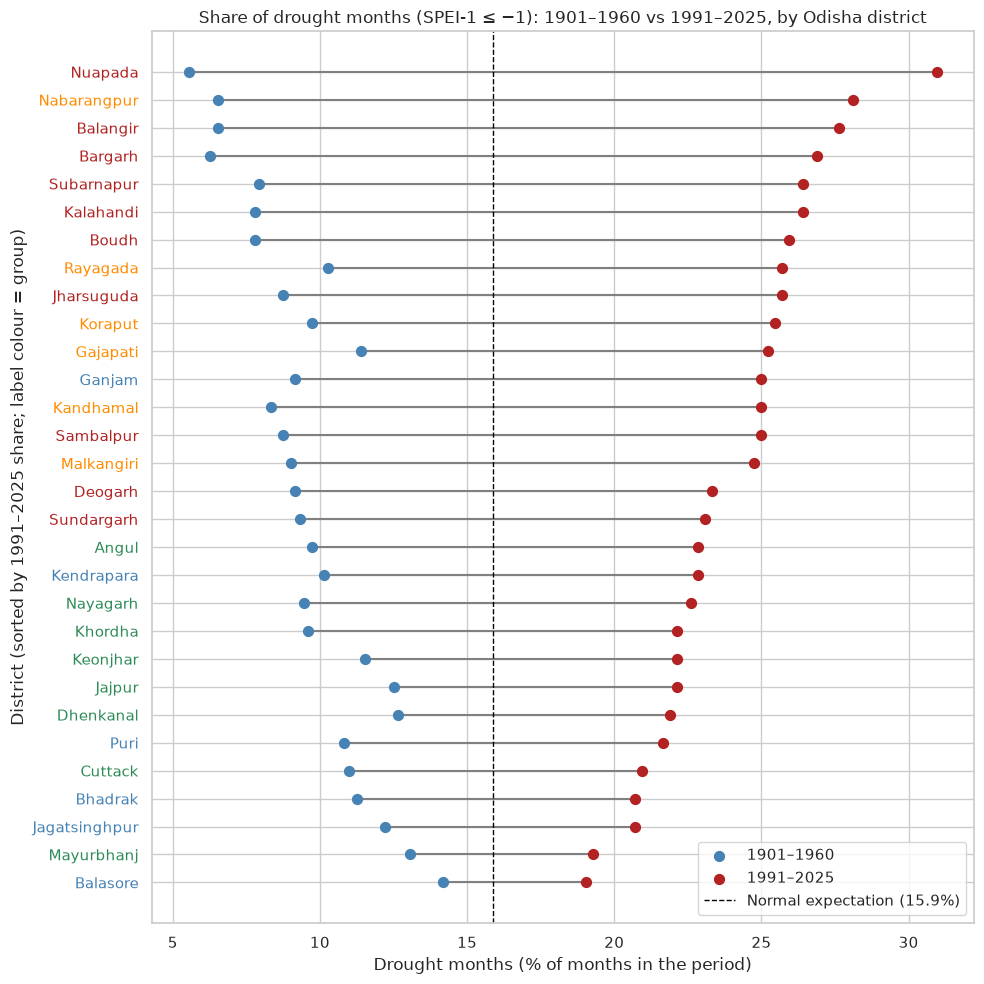

Odisha statewide: 9.4% -> 24.8% (+15.3 points)
Largest rises: {'Nuapada': 25.4, 'Nabarangpur': 21.6, 'Balangir': 21.1, 'Bargarh': 20.7, 'Kalahandi': 18.7}
Smallest rises: {'Balasore': 4.9, 'Mayurbhanj': 6.2, 'Jagatsinghpur': 8.5, 'Dhenkanal': 9.3, 'Bhadrak': 9.5}


In [22]:
fig, ax = plt.subplots(figsize=(10, 10))
y = np.arange(len(share))
ax.hlines(y, share["1901-1960"], share["1991-2025"], color="grey", linewidth=1.5)
ax.scatter(share["1901-1960"], y, color="steelblue", s=50, label="1901–1960", zorder=3)
ax.scatter(share["1991-2025"], y, color="firebrick", s=50, label="1991–2025", zorder=3)
ax.axvline(15.87, color="black", linestyle="--", linewidth=1, label="Normal expectation (15.9%)")
ax.set_yticks(y)
ax.set_yticklabels(share.index)
for tick, g in zip(ax.get_yticklabels(), share["group"]):
    tick.set_color(group_colors[g])
ax.set_title("Share of drought months (SPEI-1 ≤ −1): 1901–1960 vs 1991–2025, by Odisha district")
ax.set_xlabel("Drought months (% of months in the period)")
ax.set_ylabel("District (sorted by 1991–2025 share; label colour = group)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig(FIG / "fig11_district_early_vs_recent_dumbbell.png", dpi=150)
plt.show()
od_early = odisha.loc[odisha["period"] == "1901-1960", "drought"].mean() * 100
od_recent = odisha.loc[odisha["period"] == "1991-2025", "drought"].mean() * 100
print(f"Odisha statewide: {od_early:.1f}% -> {od_recent:.1f}% ({od_recent - od_early:+.1f} points)")
print("Largest rises:", share.sort_values("change_pp", ascending=False)["change_pp"].head(5).round(1).to_dict())
print("Smallest rises:", share.sort_values("change_pp")["change_pp"].head(5).round(1).to_dict())

**Figure 11 – Share of drought months in 1901–1960 (blue) vs 1991–2025 (red), by Odisha district.**

**Interpretation:** All 30 districts had more drought months in 1991–2025 than in 1901–1960. The biggest increases are in Nuapada (5.6% → 31.0%, +25.4 percentage points), Nabarangpur (+21.6), Balangir (+21.1), Bargarh (+20.7) and Kalahandi (+18.7). The smallest increases are in Balasore (+4.9), Mayurbhanj (+6.2), Jagatsinghpur (+8.5), Dhenkanal (+9.3) and Bhadrak (+9.5). The statewide series rose from 9.4% to 24.8% (+15.3 points), which sits inside the district range (recent shares 19.0% to 31.0%). Because the full record is standardised, an early period below 15.9% and a recent period above it go together – the useful information is in *how big* the gap is, and the gap differs a lot inside Odisha.

### 5.2 Drought events (run theory)
In **run theory** a drought *event* is a run of consecutive months with SPEI ≤ −1. For each event we record:

* **duration** – number of months in the run,
* **severity** – sum of −SPEI over the run (bigger = worse),
* **intensity** – severity ÷ duration,
* **peak** – the lowest SPEI in the run.

An event is placed in the period of its start year.

In [23]:
def find_events(df, id_col, spei_col="spei_1"):
    # Return one row per drought event (run of consecutive months with SPEI <= -1) for every area
    events = []
    for area, g in df.sort_values("date").groupby(id_col):
        g = g.dropna(subset=[spei_col]).copy()
        g["dry"] = g[spei_col] <= DROUGHT_THRESHOLD
        g["run_id"] = (g["dry"] != g["dry"].shift()).cumsum()   # new id every time dry/not-dry switches
        for _, run in g[g["dry"]].groupby("run_id"):
            events.append({id_col: area, "start": run["date"].min(), "end": run["date"].max(),
                           "duration_months": len(run), "severity": -run[spei_col].sum(),
                           "peak_spei": run[spei_col].min()})
    events = pd.DataFrame(events)
    events["intensity"] = events["severity"] / events["duration_months"]
    events["start_year"] = events["start"].dt.year
    events["period"] = events["start_year"].apply(period_of)
    return events


state_events = find_events(odisha, "area")
dist_events = find_events(dist_month, "district")
print("Odisha statewide events:", state_events.shape, "| district events:", dist_events.shape)
print("\nDuration of Odisha statewide drought events (SPEI-1), number of events:")
print(state_events["duration_months"].value_counts().sort_index().to_string())
longest = state_events.loc[state_events["duration_months"].idxmax()]
print("\nLongest statewide event:", longest["duration_months"], "months from", longest["start"].strftime("%Y-%m"), "to", longest["end"].strftime("%Y-%m"))
print("Share of district events lasting one month:", round((dist_events["duration_months"] == 1).mean() * 100, 1), "%")
print("Statewide events by period:", state_events["period"].value_counts().sort_index().to_dict())

Odisha statewide events: (184, 9) | district events: (5372, 9)

Duration of Odisha statewide drought events (SPEI-1), number of events:
duration_months
1    145
2     30
3      4
4      2
5      2
8      1

Longest statewide event: 8 months from 2000-07 to 2001-02
Share of district events lasting one month: 77.0 %
Statewide events by period: {'1901-1960': 60, '1961-1990': 52, '1991-2025': 72}


In [24]:
# SPEI-1 events are short because SPEI-1 changes a lot month to month.
# For comparison, here are Odisha events using the longer timescales.
rows = []
for col in SPEI_COLS:
    ev = find_events(odisha, "area", spei_col=col)
    rows.append({"timescale": col, "events": len(ev), "mean_duration": ev["duration_months"].mean(),
                 "max_duration": ev["duration_months"].max(),
                 "longest_event_start": ev.loc[ev["duration_months"].idxmax(), "start"].strftime("%Y-%m"),
                 "events_1901_1960": (ev["period"] == "1901-1960").sum(),
                 "events_1991_2025": (ev["period"] == "1991-2025").sum()})
pd.DataFrame(rows).round(2)

,timescale,events,mean_duration,max_duration,longest_event_start,events_1901_1960,events_1991_2025
0,spei_1,184,1.32,8,2000-07,60,72
1,spei_4,106,2.12,10,1979-05,37,36
2,spei_12,47,4.83,26,2015-10,15,16


### 5.3 Ranking the Odisha districts (1991–2025)
For the recent period we compute, for each district: drought share, number of events, mean and longest event duration,
total severity and mean intensity. The **composite rank** is the average of three ranks – drought share, total severity
and longest event – so a district needs to be bad on more than one measure to be ranked high. We also show the early-period
share and the change. The Odisha statewide values are shown for reference (they are not ranked against districts).

In [25]:
def recent_metrics(month_df, events_df, id_col):
    recent_m = month_df[month_df["period"] == "1991-2025"]
    recent_e = events_df[events_df["period"] == "1991-2025"]
    early_m = month_df[month_df["period"] == "1901-1960"]
    out = pd.DataFrame({
        "drought_share_1901_1960": early_m.groupby(id_col)["drought"].mean() * 100,
        "drought_share_1991_2025": recent_m.groupby(id_col)["drought"].mean() * 100,
        "mean_spei1_1991_2025": recent_m.groupby(id_col)["spei_1"].mean(),
        "events": recent_e.groupby(id_col).size(),
        "mean_duration": recent_e.groupby(id_col)["duration_months"].mean(),
        "longest_event": recent_e.groupby(id_col)["duration_months"].max(),
        "total_severity": recent_e.groupby(id_col)["severity"].sum(),
        "mean_intensity": recent_e.groupby(id_col)["intensity"].mean(),
    })
    out["change_pp"] = out["drought_share_1991_2025"] - out["drought_share_1901_1960"]
    # Rank 1 = most drought-prone for each measure
    out["rank_share"] = out["drought_share_1991_2025"].rank(ascending=False, method="min")
    out["rank_severity"] = out["total_severity"].rank(ascending=False, method="min")
    out["rank_longest"] = out["longest_event"].rank(ascending=False, method="min")
    out["composite_score"] = out[["rank_share", "rank_severity", "rank_longest"]].mean(axis=1)
    out["composite_rank"] = out["composite_score"].rank(method="min").astype(int)
    return out.sort_values(["composite_rank", "drought_share_1991_2025"], ascending=[True, False])


dist_rank = recent_metrics(dist_month, dist_events, "district")
dist_rank.insert(0, "group", dist_rank.index.map(district_group))
show_cols = ["composite_rank", "drought_share_1991_2025", "drought_share_1901_1960", "change_pp",
             "events", "mean_duration", "longest_event", "total_severity", "mean_intensity"]
state_ref = recent_metrics(odisha, state_events, "area")
print("Odisha statewide (reference):")
display(state_ref[show_cols[1:]].round(2))
dist_rank[["group"] + show_cols].round(2)

Odisha statewide (reference):


,drought_share_1991_2025,drought_share_1901_1960,change_pp,events,mean_duration,longest_event,total_severity,mean_intensity
area,,,,,,,,
Odisha,24.76,9.44,15.32,72,1.44,8,165.05,1.56


,group,composite_rank,drought_share_1991_2025,drought_share_1901_1960,change_pp,events,mean_duration,longest_event,total_severity,mean_intensity
district,,,,,,,,,,
Nuapada,West,1,30.95,5.56,25.40,82,1.59,7,211.25,1.56
Balangir,West,2,27.62,6.53,21.09,73,1.59,7,187.90,1.58
Nabarangpur,South,3,28.10,6.53,21.57,75,1.57,6,194.89,1.57
Kalahandi,West,4,26.43,7.78,18.65,70,1.59,7,174.23,1.53
Jharsuguda,West,5,25.71,8.75,16.96,67,1.61,8,164.84,1.48
Koraput,South,6,25.48,9.72,15.75,72,1.49,7,165.97,1.49
Boudh,West,7,25.95,7.78,18.17,72,1.51,6,166.86,1.51
Bargarh,West,8,26.90,6.25,20.65,79,1.43,5,182.70,1.57
Malkangiri,South,9,24.76,9.03,15.73,68,1.53,7,163.23,1.52


In [26]:
# Do the three measures agree? Spearman correlation between them
dist_rank[["drought_share_1991_2025", "total_severity", "longest_event", "change_pp"]].corr(method="spearman").round(2)

,drought_share_1991_2025,total_severity,longest_event,change_pp
drought_share_1991_2025,1.00,0.98,0.25,0.97
total_severity,0.98,1.00,0.28,0.97
longest_event,0.25,0.28,1.00,0.25
change_pp,0.97,0.97,0.25,1.00


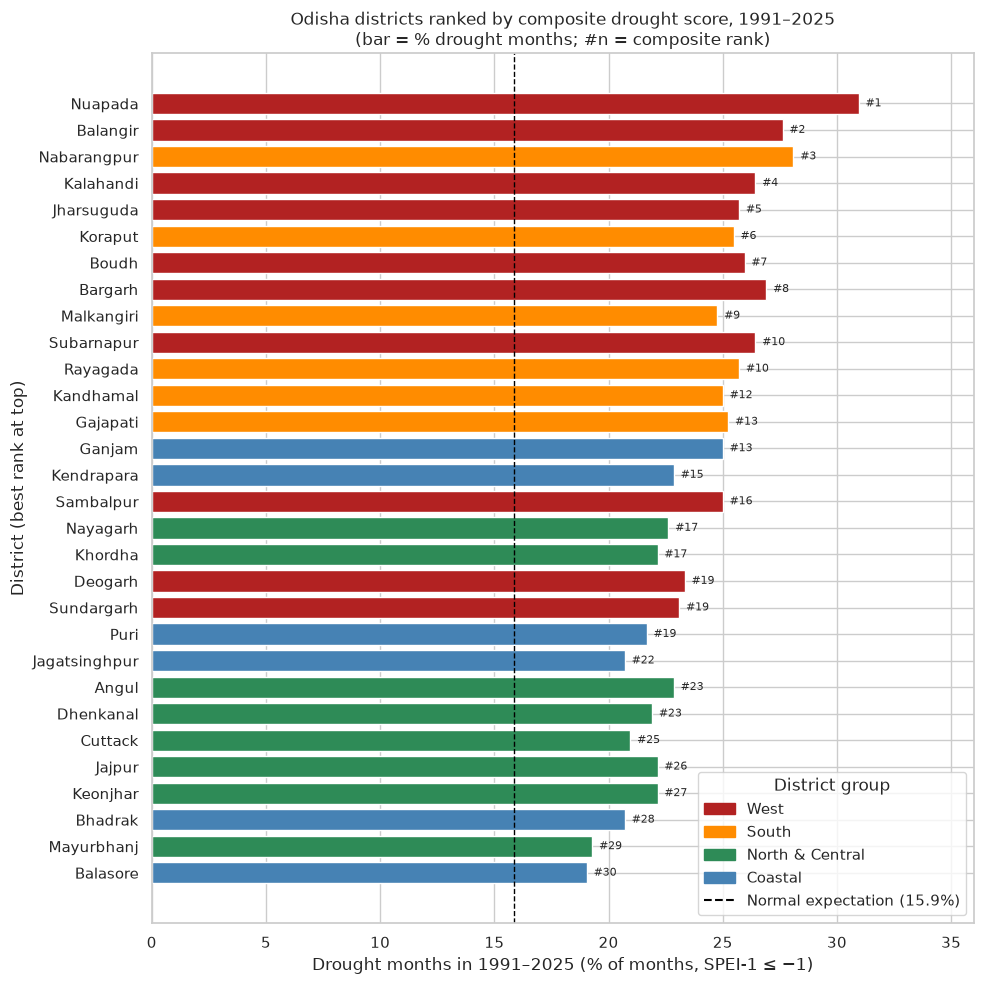

group
Coastal                      [13, 15, 19, 22, 28, 30]
North & Central      [17, 17, 23, 23, 25, 26, 27, 29]
South                           [3, 6, 9, 10, 12, 13]
West               [1, 2, 4, 5, 7, 8, 10, 16, 19, 19]


In [27]:
plot_df = dist_rank.sort_values("composite_score")
fig, ax = plt.subplots(figsize=(10, 10))
ax.barh(plot_df.index, plot_df["drought_share_1991_2025"], color=plot_df["group"].map(group_colors))
for i, (share_val, rank) in enumerate(zip(plot_df["drought_share_1991_2025"], plot_df["composite_rank"])):
    ax.text(share_val + 0.3, i, f"#{rank}", va="center", fontsize=8)
ax.axvline(15.87, color="black", linestyle="--", linewidth=1)
handles = [Patch(color=c, label=g) for g, c in group_colors.items()]
handles.append(Line2D([0], [0], color="black", linestyle="--", label="Normal expectation (15.9%)"))
ax.invert_yaxis()
ax.set_xlim(0, 36)
ax.set_title("Odisha districts ranked by composite drought score, 1991–2025\n(bar = % drought months; #n = composite rank)")
ax.set_xlabel("Drought months in 1991–2025 (% of months, SPEI-1 ≤ −1)")
ax.set_ylabel("District (best rank at top)")
ax.legend(handles=handles, title="District group", loc="lower right")
plt.tight_layout()
plt.savefig(FIG / "fig12_odisha_district_ranking_bar.png", dpi=150)
plt.show()
print(dist_rank.groupby("group")["composite_rank"].apply(lambda s: sorted(s.tolist())).to_string())

**Figure 12 – Odisha districts ranked by the composite drought score for 1991–2025.**

**Interpretation (district ranking):** The composite rank is the average of the ranks for 1991–2025 drought share, total event severity and longest event. The top five Odisha districts are **1. Nuapada** (31.0% drought months, total severity 211.2), **2. Balangir** (27.6%), **3. Nabarangpur** (28.1%), **4. Kalahandi** (26.4%) and **5. Jharsuguda** (25.7%, with the longest event, 8 months). The 11 districts ranked 10th or better are 7 West districts (Nuapada, Balangir, Kalahandi, Jharsuguda, Boudh, Bargarh, Subarnapur) and 4 South districts (Nabarangpur, Koraput, Malkangiri, Rayagada; Subarnapur and Rayagada share 10th place). The best-placed coastal district is Ganjam at joint 13th, and the three lowest are Bhadrak (28th), Mayurbhanj (29th) and Balasore (30th, 19.0%). Even the lowest district is above the 15.9% normal expectation, so all of Odisha has become drier recently, but the west and south much more so. The statewide series for reference: 24.8% drought months, 72 events, longest event 8 months, total severity 165.0. The three measures do not all agree: drought share and total severity are almost the same ranking (Spearman 0.98), but the longest event is only weakly related (0.25 with share), which is why the composite uses all three. One caution: with SPEI-1 most events are very short – 77.0% of the 5,372 district events last one month. With SPEI-12 the statewide series has fewer but much longer events (47 events, the longest 26 months starting October 2015).

### 5.4 West vs Coastal Odisha: statistical tests
We compare the 10 West districts with the 6 Coastal districts on three district-level measures. Because the groups are
small, we use both **Welch's t-test** (does not assume equal variances) and the **Mann–Whitney U test** (non-parametric,
does not assume normality).

H0: the two groups have the same mean (t-test) / the same distribution (Mann–Whitney).

In [28]:
west = dist_rank[dist_rank["group"] == "West"]
coast = dist_rank[dist_rank["group"] == "Coastal"]

rows = []
for col in ["drought_share_1991_2025", "change_pp", "total_severity"]:
    t = stats.ttest_ind(west[col], coast[col], equal_var=False)
    u = stats.mannwhitneyu(west[col], coast[col], alternative="two-sided")
    rows.append({"measure": col, "West mean": west[col].mean(), "Coastal mean": coast[col].mean(),
                 "difference": west[col].mean() - coast[col].mean(),
                 "Welch t": t.statistic, "t-test p": t.pvalue, "Mann-Whitney U": u.statistic, "MW p": u.pvalue})
west_coast_tests = pd.DataFrame(rows)
west_coast_tests.round(4)

,measure,West mean,Coastal mean,difference,Welch t,t-test p,Mann-Whitney U,MW p
0,drought_share_1991_2025,26.1429,21.6667,4.4762,4.0793,0.0017,57.5,0.0033
1,change_pp,18.3651,10.3704,7.9947,4.2570,0.0017,58.0,0.0010
2,total_severity,172.6936,133.1153,39.5783,4.6190,0.0006,58.0,0.0010


In [29]:
# Same comparison for the early period, as a check: was the West already drier in 1901-1960?
t_early = stats.ttest_ind(west["drought_share_1901_1960"], coast["drought_share_1901_1960"], equal_var=False)
u_early = stats.mannwhitneyu(west["drought_share_1901_1960"], coast["drought_share_1901_1960"], alternative="two-sided")
print(f"1901-1960 share: West mean {west['drought_share_1901_1960'].mean():.1f}%, "
      f"Coastal mean {coast['drought_share_1901_1960'].mean():.1f}% | t-test p = {t_early.pvalue:.4f}, MW p = {u_early.pvalue:.4f}")

# All four groups: Kruskal-Wallis on the recent drought share and on the change
for col in ["drought_share_1991_2025", "change_pp"]:
    kw = stats.kruskal(*[dist_rank.loc[dist_rank["group"] == g, col] for g in group_names])
    print(f"Kruskal-Wallis, 4 groups, {col}: H = {kw.statistic:.2f}, p = {kw.pvalue:.4f}")
dist_rank.groupby("group")[["drought_share_1901_1960", "drought_share_1991_2025", "change_pp", "total_severity"]].mean().loc[group_names].round(1)

1901-1960 share: West mean 7.8%, Coastal mean 11.3% | t-test p = 0.0024, MW p = 0.0023
Kruskal-Wallis, 4 groups, drought_share_1991_2025: H = 20.40, p = 0.0001
Kruskal-Wallis, 4 groups, change_pp: H = 19.98, p = 0.0002


,drought_share_1901_1960,drought_share_1991_2025,change_pp,total_severity
group,,,,
West,7.8,26.1,18.4,172.7
South,9.2,25.7,16.5,166.3
North & Central,11.2,21.8,10.6,136.8
Coastal,11.3,21.7,10.4,133.1


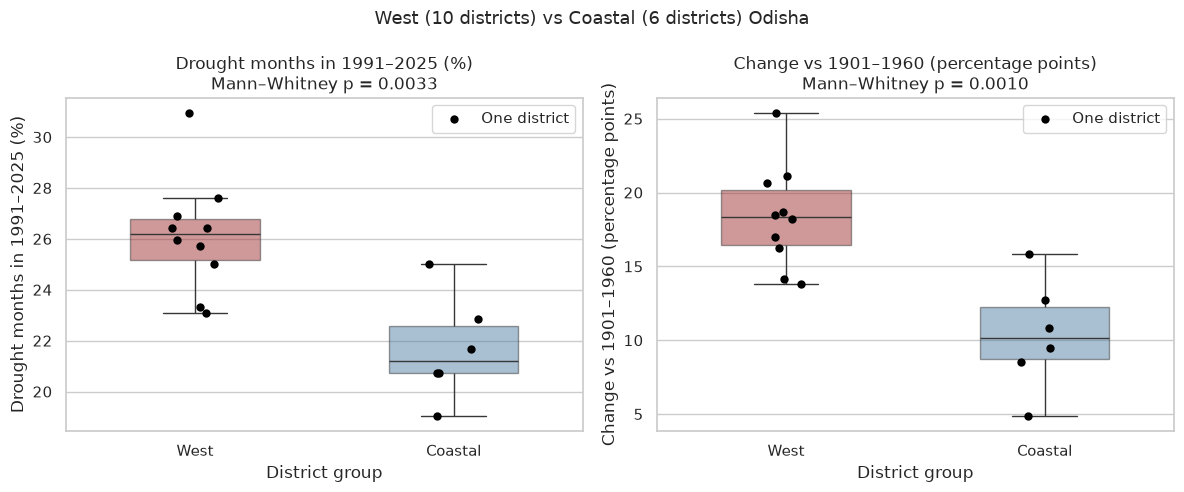

In [30]:
# Fixed seed: the strip plot moves the dots sideways at random (jitter); a seed makes the figure identical on every run
np.random.seed(42)
wc = dist_rank[dist_rank["group"].isin(["West", "Coastal"])].reset_index()
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, col, title in zip(axes, ["drought_share_1991_2025", "change_pp"],
                          ["Drought months in 1991–2025 (%)", "Change vs 1901–1960 (percentage points)"]):
    sns.boxplot(data=wc, x="group", y=col, hue="group", order=["West", "Coastal"],
                palette=group_colors, width=0.5, ax=ax, legend=False, showfliers=False, boxprops={"alpha": 0.5})
    sns.stripplot(data=wc, x="group", y=col, order=["West", "Coastal"], color="black", size=6, ax=ax,
                  label="One district")
    p = west_coast_tests.set_index("measure").loc[col, "MW p"]
    ax.set_title(f"{title}\nMann–Whitney p = {p:.4f}")
    ax.set_xlabel("District group")
    ax.set_ylabel(title)
    handles, labels = ax.get_legend_handles_labels()
    ax.legend(handles[:1], labels[:1], loc="upper right")
fig.suptitle("West (10 districts) vs Coastal (6 districts) Odisha", fontsize=13)
plt.tight_layout()
plt.savefig(FIG / "fig13_west_vs_coastal_boxplot.png", dpi=150)
plt.show()

**Figure 13 – West (10 districts) vs Coastal (6 districts) Odisha: recent drought share and change since 1901–1960.**

**Interpretation:** In 1991–2025 the West districts had on average 26.1% drought months against 21.7% for the Coastal districts (difference 4.5 points; Welch t = 4.08, p = 0.0017; Mann–Whitney U = 57.5, p = 0.0033). The **increase** since 1901–1960 is also much larger in the West (+18.4 vs +10.4 points; p = 0.0017 and 0.0010), and so is total event severity (172.7 vs 133.1; p = 0.0006 and 0.0010). Interestingly, the opposite was true in 1901–1960: the West then had *fewer* drought months than the coast (7.8% vs 11.3%, p = 0.002). So western Odisha has not always been the driest part of the state – it has changed the most. With all four groups, the recent shares are West 26.1%, South 25.7%, North & Central 21.8% and Coastal 21.7%; a Kruskal–Wallis test says the groups differ (H = 20.4, p = 0.0001), and the South behaves like the West. Caution: the groups are small (10 and 6 districts) and neighbouring districts are correlated, so these p-values should be seen as strong evidence, not proof.

### 5.5 Chi-square test: is drought frequency linked to the period?
A chi-square test of independence on a 2 × 2 table: period (1901–1960 / 1991–2025) × drought month (yes / no) for the
Odisha statewide series. H0: drought frequency does not depend on the period. (`scipy` applies Yates' continuity correction to a 2 × 2 table.)

In [31]:
od_two = odisha[odisha["period"] != "1961-1990"]
table_period = pd.crosstab(od_two["period"], od_two["drought"]).rename(columns={0: "no drought", 1: "drought"})
chi2, p, dof, expected = stats.chi2_contingency(table_period)
display(table_period)
print("Expected counts if H0 were true:")
display(pd.DataFrame(expected, index=table_period.index, columns=table_period.columns).round(1))
print(f"Chi-square = {chi2:.2f}, df = {dof}, p = {p:.2e}")

# Same test for West vs Coastal districts in 1991-2025 (pooled district-months)
wc_recent = dist_month[(dist_month["period"] == "1991-2025") & dist_month["group"].isin(["West", "Coastal"])]
table_group = pd.crosstab(wc_recent["group"], wc_recent["drought"]).rename(columns={0: "no drought", 1: "drought"})
chi2_g, p_g, dof_g, _ = stats.chi2_contingency(table_group)
display(table_group)
print(f"West vs Coastal (1991-2025, district-months): chi-square = {chi2_g:.2f}, df = {dof_g}, p = {p_g:.2e}")

# Chi-square across the four groups (1991-2025)
r4 = dist_month[dist_month["period"] == "1991-2025"]
chi2_4, p_4, dof_4, _ = stats.chi2_contingency(pd.crosstab(r4["group"], r4["drought"]))
print(f"All four groups (1991-2025, district-months): chi-square = {chi2_4:.2f}, df = {dof_4}, p = {p_4:.2e}")

drought,no drought,drought
period,,
1901-1960,652,68
1991-2025,316,104


Expected counts if H0 were true:


drought,no drought,drought
period,,
1901-1960,611.4,108.6
1991-2025,356.6,63.4


Chi-square = 47.39, df = 1, p = 5.81e-12


drought,no drought,drought
group,,
Coastal,1974,546
West,3102,1098


West vs Coastal (1991-2025, district-months): chi-square = 16.84, df = 1, p = 4.08e-05
All four groups (1991-2025, district-months): chi-square = 31.44, df = 3, p = 6.87e-07


**Interpretation (chi-square):** For Odisha as a whole, 68 of 720 months (9.4%) were drought months in 1901–1960, against 104 of 420 months (24.8%) in 1991–2025. If drought did not depend on the period we would expect about 63 drought months in 1991–2025, not 104. The chi-square test gives χ² = 47.4 (df = 1, p = 5.8 × 10⁻¹²), so drought frequency clearly depends on the period. The West vs Coastal test on pooled district-months in 1991–2025 also rejects H0 (26.1% vs 21.7%, χ² = 16.8, p = 4.1 × 10⁻⁵), and so does the test across all four groups (χ² = 31.4, df = 3, p = 6.9 × 10⁻⁷). But these pooled p-values are too optimistic because months from neighbouring districts are not independent; the district-level tests above are more trustworthy.

## 6. Seasonality

### 6.1 Year × month heatmap for Odisha
Each cell is one month. Red = dry (negative SPEI-1), blue = wet.

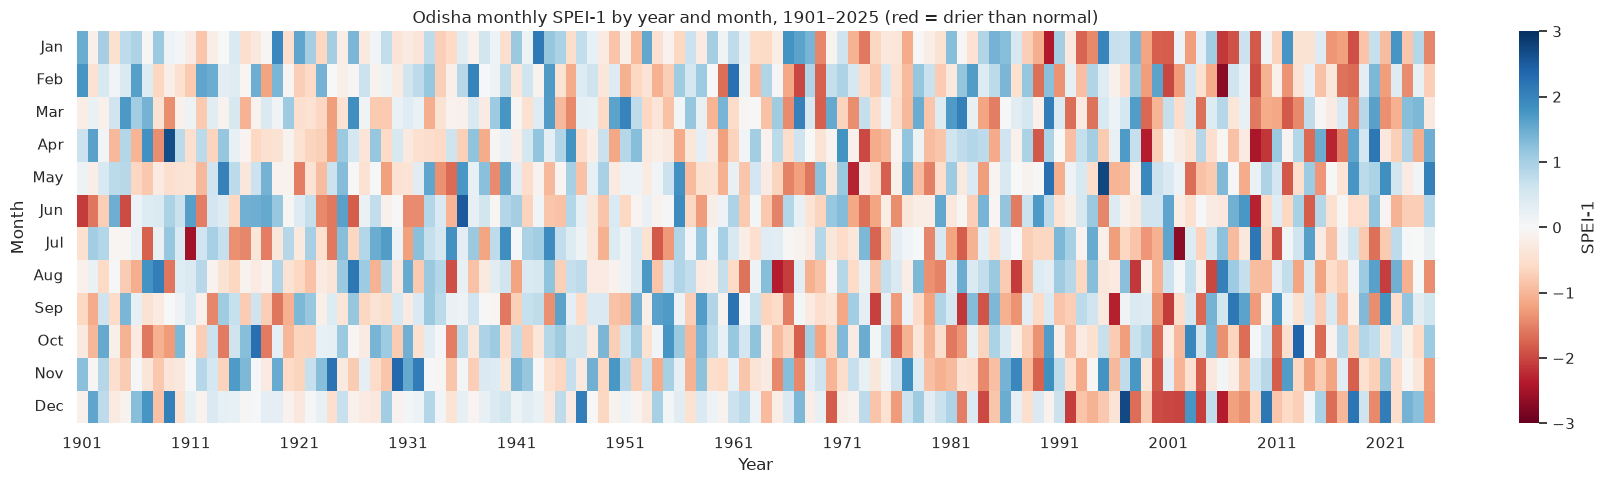

In [32]:
heat = odisha.pivot(index="month", columns="year", values="spei_1")
fig, ax = plt.subplots(figsize=(18, 5))
sns.heatmap(heat, cmap="RdBu", center=0, vmin=-3, vmax=3, ax=ax, cbar_kws={"label": "SPEI-1"})
ax.set_xticks(np.arange(0, heat.shape[1], 10) + 0.5)
ax.set_xticklabels(heat.columns[::10], rotation=0)
ax.set_yticklabels(["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"], rotation=0)
ax.set_title("Odisha monthly SPEI-1 by year and month, 1901–2025 (red = drier than normal)")
ax.set_xlabel("Year")
ax.set_ylabel("Month")
plt.tight_layout()
plt.savefig(FIG / "fig14_odisha_year_month_heatmap.png", dpi=150)
plt.show()

In [33]:
# Drought share (%) by season and period for Odisha
season_order = ["Winter (JF)", "Pre-monsoon (MAM)", "Monsoon (JJAS)", "Post-monsoon (OND)"]
season_period = (odisha.groupby(["season", "period"])["drought"].mean().unstack() * 100).loc[season_order]
season_period["change_pp"] = season_period["1991-2025"] - season_period["1901-1960"]
season_period.round(1)

period,1901-1960,1961-1990,1991-2025,change_pp
season,,,,
Winter (JF),4.2,16.7,37.1,33.0
Pre-monsoon (MAM),10.6,17.8,24.8,14.2
Monsoon (JJAS),13.8,22.5,17.1,3.4
Post-monsoon (OND),6.1,20.0,26.7,20.6


In [34]:
# Chi-square: does drought frequency depend on the season? (full record, and each period separately)
for label, df in [("1901-2025", odisha), ("1901-1960", odisha[odisha["period"] == "1901-1960"]),
                  ("1991-2025", odisha[odisha["period"] == "1991-2025"])]:
    table = pd.crosstab(df["season"], df["drought"])
    chi2, p, dof, _ = stats.chi2_contingency(table)
    print(f"{label}: chi-square = {chi2:6.2f}, df = {dof}, p = {p:.4f}")

# Dry season (Oct-May) vs monsoon (Jun-Sep): change in drought share, statewide and by district group
def part_change(df):
    part = np.where(df["month"].between(6, 9), "monsoon", "dry_season")
    d = df.assign(part=part)
    early = d[d["year"] <= 1960].groupby("part")["drought"].mean() * 100
    recent = d[d["year"] >= 1991].groupby("part")["drought"].mean() * 100
    return (recent - early)
season_change_state = part_change(odisha)
print("\nOdisha statewide change (points): dry season", round(season_change_state["dry_season"], 1), "| monsoon", round(season_change_state["monsoon"], 1))
group_part = pd.DataFrame({g: part_change(dist_month[dist_month["group"] == g]) for g in group_names}).T
group_part.round(1)

1901-2025: chi-square =   0.42, df = 3, p = 0.9366
1901-1960: chi-square =  11.71, df = 3, p = 0.0085
1991-2025: chi-square =  10.33, df = 3, p = 0.0160

Odisha statewide change (points): dry season 21.3 | monsoon 3.4


part,dry_season,monsoon
West,23.6,7.9
South,23.0,3.4
North & Central,15.7,0.3
Coastal,14.8,1.4


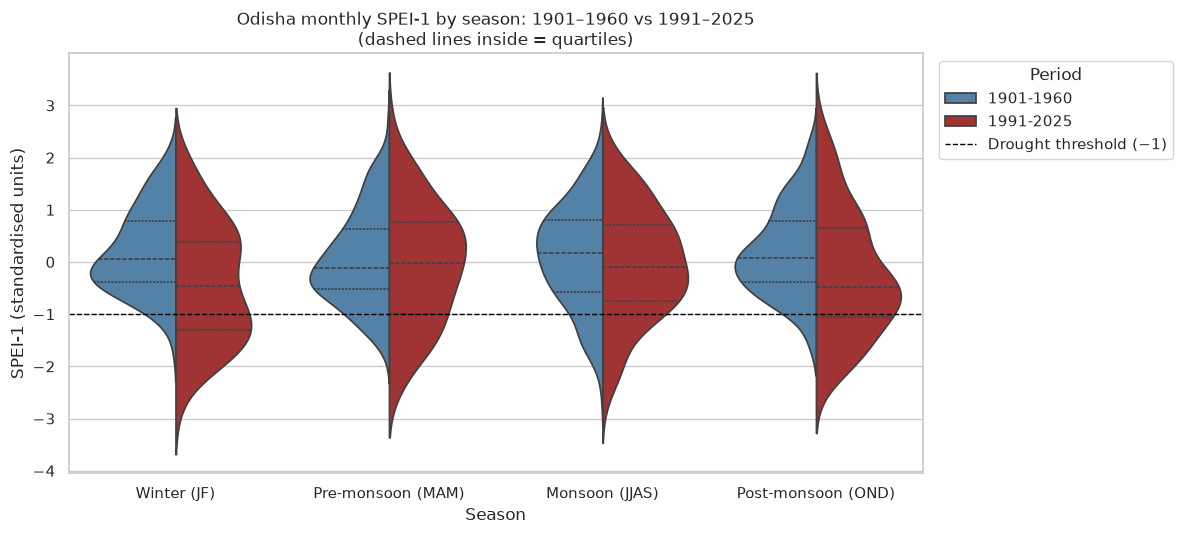

period,1901-1960,1991-2025
season,,
Winter (JF),0.06,-0.47
Pre-monsoon (MAM),-0.11,-0.02
Monsoon (JJAS),0.18,-0.10
Post-monsoon (OND),0.08,-0.47


In [35]:
viol = odisha[odisha["period"] != "1961-1990"]
fig, ax = plt.subplots(figsize=(12, 5.5))
sns.violinplot(data=viol, x="season", y="spei_1", hue="period", order=season_order, split=True, inner="quart",
               palette={"1901-1960": "steelblue", "1991-2025": "firebrick"}, ax=ax)
ax.axhline(DROUGHT_THRESHOLD, color="black", linestyle="--", linewidth=1, label="Drought threshold (−1)")
ax.set_title("Odisha monthly SPEI-1 by season: 1901–1960 vs 1991–2025\n(dashed lines inside = quartiles)")
ax.set_xlabel("Season")
ax.set_ylabel("SPEI-1 (standardised units)")
ax.legend(title="Period", loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.savefig(FIG / "fig15_odisha_season_violin.png", dpi=150)
plt.show()
viol.groupby(["season", "period"])["spei_1"].median().unstack().loc[season_order].round(2)

**Figure 14 – Odisha SPEI-1 by year and month. Figure 15 – Odisha SPEI-1 by season, 1901–1960 vs 1991–2025.**

**Interpretation:** The heatmap is mostly mixed red and blue before about 1960 and gets more red afterwards, especially in the Jan–Feb and Oct–Dec rows in the last 30 years. The season table confirms this: in 1991–2025 **winter (JF)** months were in drought 37.1% of the time compared with only 4.2% in 1901–1960 (+33.0 points), post-monsoon (OND) went from 6.1% to 26.7%, pre-monsoon from 10.6% to 24.8%, while the **monsoon (JJAS) changed only from 13.8% to 17.1%** (+3.4). Taken together, the dry season (October–May) rose by +21.3 points against +3.4 for the monsoon. This holds in every district group: dry season +23.6 (West), +23.0 (South), +15.7 (North & Central) and +14.8 (Coastal); the monsoon rose most in the West (+7.9) and hardly at all in the other groups (+3.4, +0.3, +1.4). In the violin plot the median winter and post-monsoon SPEI-1 dropped from about +0.06/+0.08 to −0.47, while the monsoon median only moved from +0.18 to −0.10. Over the whole record the season does not matter (χ² = 0.42, p = 0.94), but inside each period it does (1901–1960: p = 0.009, monsoon most drought-prone; 1991–2025: p = 0.016, winter most drought-prone). So the recent rise in drought months in Odisha comes mostly from the dry season. A possible reason is that SPEI includes evapotranspiration (which rises with temperature) and dry-season rainfall is small, but we cannot test this with the SPEI data alone.

## 7. Outliers: IQR vs Z-score
* **IQR rule** (same as notebook 01): outlier if below Q1 − 1.5·IQR or above Q3 + 1.5·IQR, using all values of the table together.
* **Z-score rule:** z = (value − mean of that area) ÷ standard deviation of that area; outlier if |z| > 3.

We apply both to SPEI-1 and SPEI-12 in the Odisha statewide table and in the Odisha district table and compare.

In [36]:
def compare_outliers(df, id_col, col):
    data = df.dropna(subset=[col]).copy()
    q1, q3 = data[col].quantile([0.25, 0.75])
    low, high = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
    data["iqr_flag"] = (data[col] < low) | (data[col] > high)
    group = data.groupby(id_col)[col]
    data["z"] = (data[col] - group.transform("mean")) / group.transform("std")
    data["z_flag"] = data["z"].abs() > 3
    summary = {"column": col, "n": len(data), "IQR fences": f"{low:.2f} to {high:.2f}",
               "IQR outliers": int(data["iqr_flag"].sum()), "Z outliers (|z|>3)": int(data["z_flag"].sum()),
               "flagged by both": int((data["iqr_flag"] & data["z_flag"]).sum()),
               "IQR only": int((data["iqr_flag"] & ~data["z_flag"]).sum()),
               "Z only": int((~data["iqr_flag"] & data["z_flag"]).sum()),
               "low (dry) outliers, IQR": int((data[col] < low).sum())}
    return summary, data


rows = []
flagged = {}
for label, df, id_col in [("Odisha statewide", odisha, "area"), ("Odisha districts", dist_month, "district")]:
    for col in ["spei_1", "spei_12"]:
        s, data = compare_outliers(df, id_col, col)
        rows.append({"table": label, **s})
        flagged[(label, col)] = data
outlier_compare = pd.DataFrame(rows)
# If the data were exactly normal, 0.27% of values would have |z| > 3
outlier_compare["expected |z|>3 if normal"] = (outlier_compare["n"] * 2 * stats.norm.sf(3)).round(0).astype(int)
outlier_compare

,table,column,n,IQR fences,IQR outliers,Z outliers (|z|>3),flagged by both,IQR only,Z only,"low (dry) outliers, IQR",expected |z|>3 if normal
0,Odisha statewide,spei_1,1500,-2.75 to 2.79,0,0,0,0,0,0,4
1,Odisha statewide,spei_12,1489,-2.55 to 2.62,19,0,0,19,0,16,4
2,Odisha districts,spei_1,45000,-2.85 to 2.83,29,11,11,18,0,13,121
3,Odisha districts,spei_12,44670,-2.81 to 2.81,58,26,26,32,0,27,121


In [37]:
# The most extreme dry district-months by Z-score
d = flagged[("Odisha districts", "spei_1")]
d[d["z_flag"] & (d["z"] < 0)].nsmallest(8, "z")[["district", "date", "spei_1", "z", "iqr_flag"]].round({"spei_1": 2, "z": 2})

,district,date,spei_1,z,iqr_flag
10734,Deogarh,1920-07-01,-3.62,-3.63,True
19148,Jajpur,1996-09-01,-3.58,-3.60,True
6856,Bhadrak,1972-05-01,-3.20,-3.22,True
25261,Kendrapara,2006-02-01,-3.04,-3.05,True
31028,Malkangiri,1986-09-01,-3.03,-3.04,True
25148,Kendrapara,1996-09-01,-3.00,-3.01,True
43267,Subarnapur,2006-08-01,-3.00,-3.01,True


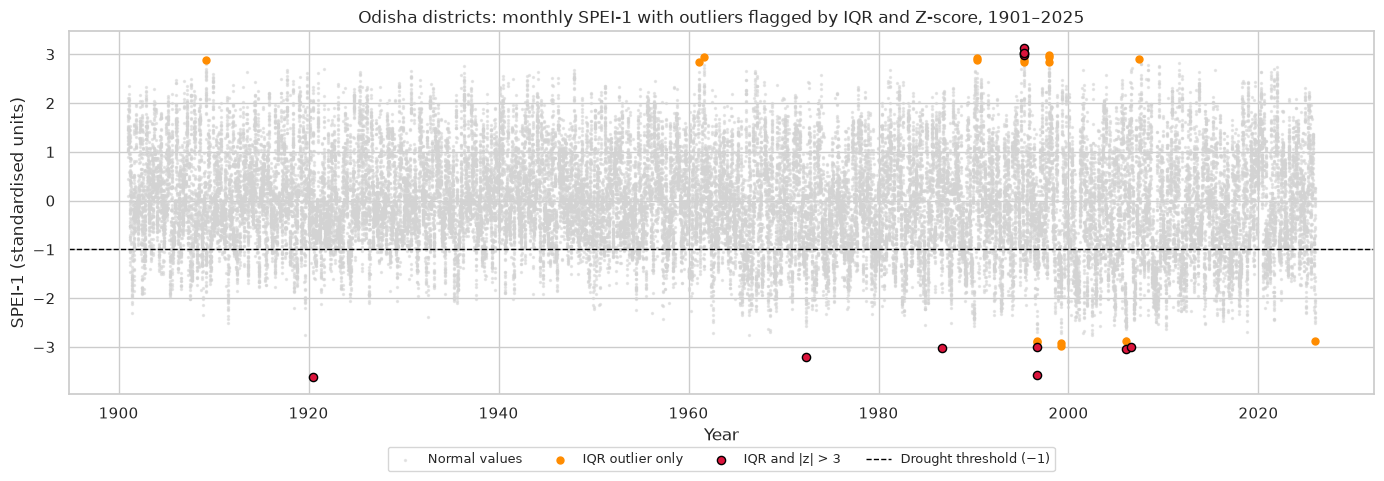

In [38]:
d = flagged[("Odisha districts", "spei_1")]
fig, ax = plt.subplots(figsize=(14, 5))
normal = d[~d["iqr_flag"] & ~d["z_flag"]]
ax.scatter(normal["date"], normal["spei_1"], s=2, color="lightgrey", alpha=0.5, label="Normal values")
iqr_only = d[d["iqr_flag"] & ~d["z_flag"]]
ax.scatter(iqr_only["date"], iqr_only["spei_1"], s=25, color="darkorange", label="IQR outlier only")
both_flag = d[d["iqr_flag"] & d["z_flag"]]
ax.scatter(both_flag["date"], both_flag["spei_1"], s=35, color="crimson", edgecolor="black", label="IQR and |z| > 3")
z_only = d[~d["iqr_flag"] & d["z_flag"]]
if len(z_only):
    ax.scatter(z_only["date"], z_only["spei_1"], s=25, color="purple", label="|z| > 3 only")
ax.axhline(DROUGHT_THRESHOLD, color="black", linestyle="--", linewidth=1, label="Drought threshold (−1)")
ax.set_title("Odisha districts: monthly SPEI-1 with outliers flagged by IQR and Z-score, 1901–2025")
ax.set_xlabel("Year")
ax.set_ylabel("SPEI-1 (standardised units)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.13), fontsize=9, ncol=5)
plt.tight_layout()
plt.savefig(FIG / "fig16_outliers_iqr_vs_z_scatter.png", dpi=150)
plt.show()

**Figure 16 – Odisha district SPEI-1 with outliers flagged by the IQR rule and by |z| > 3.**

**Interpretation:** The IQR fences for SPEI-1 are −2.75 to +2.79 for the statewide series and −2.85 to +2.83 for the districts. For the statewide series **neither rule flags a single SPEI-1 value** (the lowest is −2.72); for SPEI-12 the IQR rule flags 19 statewide months (16 of them dry) and the Z-score rule none. For the districts the IQR rule flags 29 values and the Z-score rule 11 for SPEI-1 (SPEI-12: 58 vs 26). The IQR fences are *lower* than 3 standard deviations, so the IQR rule flags more values; every Z-score outlier is also an IQR outlier ("Z only" = 0), so the two methods agree on the most extreme months and differ only on the borderline ones. If SPEI were exactly normal we would expect about 121 district-months with |z| > 3; we see only 11, because the tails are lighter than normal (negative kurtosis). The most extreme dry district-months are real, known dry spells – e.g. Jajpur, Kendrapara, Cuttack and Bhadrak in September 1996 and Kendrapara in February 2006 – and the two local-only cases are Deogarh in July 1920 (−3.62) and Subarnapur in August 2006 (−3.00). We therefore **keep all outliers**: they are the extreme droughts this project is about, there are no sentinel or impossible values, and removing them would make droughts look milder than they were.

## 8. Saving the new tables

In [39]:
trend_state = trend_main.copy()
outputs = {
    "drought_events_odisha_state.csv": state_events,
    "drought_events_odisha_districts.csv": dist_events,
    "ranking_odisha_districts_1991_2025.csv": dist_rank.reset_index(),
    "trends_odisha_districts.csv": dist_trends,
    "trends_odisha_state.csv": trend_state,
    "west_vs_coastal_tests.csv": west_coast_tests,
    "district_vs_state_coherence.csv": coherence,
    "decade_group_drought_share.csv": decade_group.reset_index(),
}
saved = []
for name, table in outputs.items():
    table.to_csv(CLEAN / name, index=False)
    saved.append({"file": f"data/clean/{name}", "rows": table.shape[0], "columns": table.shape[1]})
pd.DataFrame(saved)

,file,rows,columns
0,data/clean/drought_events_odisha_state.csv,184,9
1,data/clean/drought_events_odisha_districts.csv,5372,9
2,data/clean/ranking_odisha_districts_1991_2025.csv,30,16
3,data/clean/trends_odisha_districts.csv,90,9
4,data/clean/trends_odisha_state.csv,4,8
5,data/clean/west_vs_coastal_tests.csv,3,8
6,data/clean/district_vs_state_coherence.csv,30,6
7,data/clean/decade_group_drought_share.csv,13,6


In [40]:
sorted(p.name for p in FIG.glob("fig*.png"))

['fig01_odisha_spei1_histogram.png',
 'fig02_odisha_spei12_timeseries.png',
 'fig03_odisha_drought_months_per_decade.png',
 'fig04_odisha_spei1_boxplot_by_month.png',
 'fig05_odisha_districts_drought_share.png',
 'fig06_spei_distributions_hist_kde.png',
 'fig07_odisha_vs_districts_and_timescales.png',
 'fig08_odisha_district_correlation_heatmap.png',
 'fig09_odisha_rolling_trend_line.png',
 'fig10_district_trend_bar.png',
 'fig11_district_early_vs_recent_dumbbell.png',
 'fig12_odisha_district_ranking_bar.png',
 'fig13_west_vs_coastal_boxplot.png',
 'fig14_odisha_year_month_heatmap.png',
 'fig15_odisha_season_violin.png',
 'fig16_outliers_iqr_vs_z_scatter.png']

## 9. Key findings

1. **SPEI is nearly normal** at all three timescales (|skewness| ≤ 0.15, excess kurtosis −0.44 to +0.06), with slightly lighter tails than a normal curve; formal tests reject exact normality mostly because the samples are large.
2. **The districts follow the statewide series only partly:** mean r = 0.84 for monthly SPEI-1 (0.69 to 0.93); 72.0% of district drought months are also statewide drought months, so 28% are local droughts that the statewide average does not show.
3. **Drought is regional inside Odisha:** monsoon SPEI-4 correlates at r = 0.65 within district groups but 0.42 between groups; West vs Coastal districts correlate at only r = 0.37.
4. **Odisha is getting drier outside the monsoon:** yearly mean SPEI-1 has a significant drying trend (Mann–Kendall tau = −0.22, p = 0.0003; −0.028 per decade) and drought months per year rise significantly (tau = 0.33), but the monsoon (Sep SPEI-4) and calendar-year (Dec SPEI-12) indicators show no significant trend.
5. **The dry season drives the change:** winter (JF) drought months rose from 4.2% (1901–1960) to 37.1% (1991–2025) and post-monsoon from 6.1% to 26.7%, while the monsoon rose only from 13.8% to 17.1%. Overall, Odisha drought months rose from 9.4% to 24.8% (χ² = 47.4, p < 0.001). The 2000s were the worst decade in every district group.
6. **District ranking (1991–2025, composite):** 1 Nuapada (31.0%), 2 Balangir, 3 Nabarangpur, 4 Kalahandi, 5 Jharsuguda; no coastal district is in the top 12 (Ganjam is joint 13th); Balasore is 30th. All 30 districts had more drought months recently, from +4.9 (Balasore) to +25.4 points (Nuapada).
7. **Trends by group:** all 10 West districts have a significant drying trend, but none of the 6 Coastal districts does (19 of 30 overall).
8. **West vs Coastal Odisha:** recent drought share 26.1% vs 21.7% (Welch t-test p = 0.0017, Mann–Whitney p = 0.0033), and the change since 1901–1960 is +18.4 vs +10.4 points (p ≤ 0.002). In 1901–1960 the West was actually *less* drought-prone (7.8% vs 11.3%), so the west has changed the most. The South behaves like the West (25.7%).

**Limitations:** SPEI-1 drought events are mostly one month long; the West/Coastal tests use small groups of correlated districts; we cannot separate rainfall and temperature effects with SPEI alone; there is no ENSO or rainfall data in the atlas.

**Next (notebook 03):** district maps from the shapefiles and publication-style charts, and an interactive animated district map.